[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/owlmt/QML/blob/main/01_Network_Intrusion_Detection/HybridQNN_EncodingComparison_Kadi2025.ipynb)

# Hybrid quantum-classical networks for intrusion detection: comparing Amplitude, Angle, IQP and QAOA encodings (Kadi et al. 2025), step by step

**Paper.** Adam Kadi, Aymene Selamnia, Zakaria Abou El Houda, Hajar Moudoud, Bouziane Brik and Lyes Khoukhi,
*"An In-Depth Comparative Study of Quantum-Classical Encoding Methods for Network Intrusion Detection"*,
IEEE Open Journal of the Communications Society, vol. 6, pp. 1129-1148, 2025.
DOI: [10.1109/OJCOMS.2025.3537957](https://doi.org/10.1109/OJCOMS.2025.3537957).
The authors' code is at `github.com/ReSEC-Laboratory/QIDS` (one Colab notebook, PennyLane + Keras); this notebook was written from the paper text and from that public notebook, with PyTorch instead of Keras (see the table below).

**What this notebook does.** The paper asks one question: *when a classical network flow has to be loaded into a quantum circuit, how much does the way it is encoded matter?*
It trains the same small hybrid model (an encoding circuit, a trainable entangling circuit, Pauli measurements, one sigmoid neuron) with four encodings
(Amplitude, Angle, IQP, QAOA embedding) and two trainable circuits (StronglyEntanglingLayers, BasicEntanglerLayers) on two public IoT intrusion datasets
(CICIoT2023 for DDoS flows, Edge-IIoTset for mixed attacks), and studies the effect of circuit depth, number of qubits/features, rotation axis and measurement basis, and two circuit-quality measures (expressibility, entanglement capability).
This notebook rebuilds every one of those experiments on a CPU simulator, trains a classical baseline on identical inputs, and prints the paper's numbers next to its own with an explicit verdict for each claim.

**How to run.** Google Colab, CPU runtime, *Runtime -> Run all*. `FAST_MODE = True` is a class demo of roughly 7 to 10 minutes (it shrinks the main model to 4 qubits / depth 4 and uses 900 rows). The outputs stored in this notebook come from `FAST_MODE = False` (8 qubits, depth 8, 2000 balanced rows per dataset, the paper's epoch counts), which took about 2.3 hours on a shared CPU machine (the model code is identical; most of the time is the 8-qubit, depth-8 simulation with Adam on batches of 50-100). The datasets are downloaded from Hugging Face mirrors (public, no token needed; if you have a token it is read from `HF_TOKEN` in the environment or in Colab *Secrets* and never printed).

**What you get at the end.** Dataset plots, the eight circuits that are really executed, the Table 4 style comparison (accuracy / precision / recall / F1 for 4 encodings x 2 entanglers x 2 datasets), accuracy-versus-epoch, versus-depth, versus-qubits and rotation-by-measurement figures, expressibility and entanglement curves, classical baselines, and a claim-by-claim comparison with the paper.

## The paper in one page

**Problem.** Network intrusion detection (NIDS) on IoT traffic, binary decision: *benign* (class 0) versus *attack* (class 1). Quantum machine learning needs classical features loaded into a quantum state; the loading step ("encoding") is argued to matter at least as much as the model.

**Method (Section III and Algorithm 1).**
1. *Pre-processing:* clean (duplicates, missing values by mean imputation, one-hot for categoricals), scale to [0, 1], keep the top-*k* features with **XGBoost importance** (CICIoT2023) or **ANOVA F-value** (Edge-IIoTset), normalise to unit norm where the encoding needs it.
2. *Hybrid model (Fig. 1):* encoding circuit -> trainable entangling circuit (`StronglyEntanglingLayers` or `BasicEntanglerLayers`, depth 8 by default) -> expectation values of one Pauli operator on every qubit -> one dense sigmoid neuron.
   Quantum weights start uniform in [-pi, pi]; Adam, binary cross-entropy, batch 50 or 100, 5 or 10 epochs.
3. *Four encodings:* Amplitude (data in the 2^n amplitudes, normalised), Angle (one rotation per qubit), IQP (diagonal Z and ZZ phases between Hadamards), QAOA embedding (RX feature layers + trainable ZZ / RY Ising layers).
4. *Evaluator:* accuracy, precision, recall, F1, confusion matrix, and two circuit measures: **expressibility** (KL divergence of the fidelity distribution from Haar) and **entanglement capability** (average Meyer-Wallach measure).

**Data.** CICIoT2023 ("Dataset 2", flows, benign versus DDoS HTTP/SYN/PSHACK/RSTFIN floods, 38 features) and Edge-IIoTset ("Dataset 1", packets, benign versus 13 attack types, 61 features).

**Claims that can be checked numerically (all on a PennyLane `default.qubit` simulator).**
* Fig. 8 (Amplitude embedding + StronglyEntanglingLayers, Adam, BCE, 10 epochs, batch 50): CICIoT2023 reaches **85 %** with 2 qubits / 4 features and **89 %** with 4 qubits / 16 features; Edge-IIoTset **70 %** and **73 %**.
* Fig. 5 (Angle embedding, 5 epochs, batch 50, CICIoT2023): the best rotation/measurement combination (Y rotation with Pauli-X or Pauli-Y measurement) reaches **93.08 %** validation accuracy; Z rotations measured in X stay near **50 %**.

**Claims that are qualitative in the text** (the numbers of Table 4 and of Figs. 6, 7, 9, 10 are only in the figures, which cannot be read from the PDF text layer): Amplitude is stable and strong on both datasets; Angle gains little from extra layers; IQP is weaker; QAOA embedding is near perfect with the weakly entangling circuit on the DDoS data; accuracy generally rises with depth, especially for QAOA and Amplitude; DDoS flows (CICIoT2023) are easier than the mixed-attack packets of Edge-IIoTset; Amplitude has the highest entanglement capability.

## What follows the paper and what had to be chosen

| Item | Paper | This notebook |
|---|---|---|
| Framework | PennyLane `default.qubit` + Keras `KerasLayer` (TensorFlow), Colab | PennyLane `default.qubit` with the **same templates** + PyTorch `TorchLayer` (Keras 3 is not supported by `KerasLayer` in current PennyLane). Same Adam, BCE, sigmoid neuron `# CHOICE:` |
| Datasets | CICIoT2023 (38 features) and Edge-IIoTset (61 features) | Same two datasets from Hugging Face mirrors. CICIoT2023 mirror has **39** numeric features; one dataset-specific mix of two mirrors is needed because no single mirror holds all four DDoS floods `# CHOICE:` |
| CICIoT2023 task | Benign vs DDoS HTTP / SYN / PSHACK / RSTFIN floods | Same five labels, balanced 50 % benign / 50 % attack (attack split equally over the four floods) `# CHOICE:` |
| Edge-IIoTset task | Benign vs 13 attack types, 61 features | Same; identifier and payload columns are dropped, remaining text columns one-hot encoded, balanced 50 / 50 `# CHOICE:` |
| Sample sizes | not stated | `N_TOTAL` samples (2000 full, 900 fast) because the simulator is slow `# CHOICE:` |
| Train / test split | not stated (code: 67 / 33) | stratified 67 / 33, plus 15 % of the training part as validation for the epoch curves `# CHOICE:` |
| Feature selection | XGBoost (CICIoT2023), ANOVA (Edge-IIoTset); *k* = 8 in the public code | same; fitted on the training split only |
| Scaling | [0, 1] then unit norm | [0, 1] min-max fitted on training; unit norm applied by `AmplitudeEmbedding(normalize=True)`; a 1e-6 offset avoids all-zero rows `# CHOICE:` |
| Qubits / features | 8 qubits, 8 features (code); Fig. 8 sweeps 2-4 qubits | same; layer sweep (Fig. 7) and expressibility (Fig. 9) use 4 qubits to keep the sweep affordable `# CHOICE:` |
| Trainable circuit | StronglyEntanglingLayers (range 1) and BasicEntanglerLayers, depth 8. Eq. 16 says Ry rotations, the Fig. 4 caption says Rx and Rz, the public code uses PennyLane's default | PennyLane defaults: `StronglyEntanglingLayers` (Rot + CNOT), `BasicEntanglerLayers` with **RX** rotations `# CHOICE:` |
| Measurement | Pauli-Z in the text; the public code uses Pauli-X for Amplitude / Angle and Pauli-Z for IQP / QAOA | follows the public code `# CHOICE:` |
| QAOA embedding | `QAOAEmbedding` followed by the entangling layers, both depth 8 (code) | same |
| Optimiser | Adam, BCE, learning rate not stated (Keras default 1e-3) | Adam; the learning rate is a constant `LR`: **0.01** in the main runs because we have about 100 times fewer optimisation steps than the authors' full-dataset training, and the paper-faithful 1e-3 is run once for comparison `# CHOICE:` |
| Epochs / batch | 10 epochs batch 100 (code, Table 4, Fig 6), 5 epochs batch 50 (Figs 5, 7), 10 epochs batch 50 (Fig 8) | the same |
| Initial weights | uniform in [-pi, pi] | same |
| Seeds | not stated | `SEED = 42`; Fig. 8 repeated over 2 seeds in the full run |
| Expressibility / entanglement | formulas (22)-(27); sample count not stated | 4 qubits, sampled input rows from the training split and random weights in [-pi, pi], 75 histogram bins `# CHOICE:` |
| Table 4 values | in a figure-like table, not recoverable from the text | cannot be compared numerically; text statements are checked qualitatively |

In [1]:
# 0. Installs (pinned to the versions this notebook was tested with). Colab already ships torch, numpy, pandas, scikit-learn, matplotlib.
import sys, subprocess
IN_COLAB = "google.colab" in sys.modules

def _need_install():
    try:
        import pennylane, torch, xgboost, huggingface_hub, pyarrow  # noqa: F401
        return False
    except Exception:
        return True

if IN_COLAB or _need_install():
    subprocess.run([sys.executable, "-m", "pip", "-q", "install", "pennylane==0.45.1", "xgboost", "huggingface_hub", "pyarrow"], check=False)
    print("Installed. If an import below fails, restart the session (Runtime -> Restart session) and run again.")
else:
    print("Required libraries already available; nothing to install.")

Required libraries already available; nothing to install.


In [2]:
# 1. Configuration: every tunable constant lives here.
SEED = 42
FAST_MODE = False          # True: ~10 min class demo; False: larger budget (see below), about 1-1.5 h on a CPU

TEST_SIZE = 0.33          # paper code: 0.33
VAL_FRACTION = 0.15       # part of the training split used only for the epoch curves
BATCH_MAIN = 100          # Table 4 / Fig. 6 (public code)
BATCH_SMALL = 50          # Figs. 5, 7, 8
LR = 0.01                 # CHOICE: Adam learning rate (paper: Keras default 1e-3, not stated); see section 9 for the 1e-3 check
LR_PAPER = 1e-3

if FAST_MODE:
    N_QUBITS = 4                # FAST demo uses a 4-qubit, depth-4 main model (paper / public code: 8 qubits, depth 8)
    N_LAYERS = 4
    N_TOTAL = 900               # balanced rows per dataset (train + test)
    EPOCHS_MAIN = 5             # paper: 10
    EPOCHS_SMALL = 3            # paper: 5
    EPOCHS_FIG8 = 5             # paper: 10
    LAYER_GRID = [1, 4]         # paper: 1..12
    FIG5_MEAS = ["X", "Z"]      # paper: X, Y, Z, Hadamard
    FIG8_QUBITS = [2, 3, 4]
    FIG8_SEEDS = [SEED]
    EXPR_PAIRS = 60             # fidelity pairs for expressibility
    EXPR_LAYERS = [1, 2, 4]
else:
    N_QUBITS = 8                # qubits = selected features of the main model (public code: 8)
    N_LAYERS = 8                # depth of the trainable circuit and of the QAOA embedding (paper Fig. 6: 8)
    N_TOTAL = 2000
    FIG5_MEAS = ["X", "Y", "Z", "H"]
    EPOCHS_MAIN = 10
    EPOCHS_SMALL = 5
    EPOCHS_FIG8 = 10
    LAYER_GRID = [1, 2, 4, 8, 12]
    FIG8_QUBITS = [2, 3, 4]
    FIG8_SEEDS = [SEED, SEED + 1]
    EXPR_PAIRS = 300
    EXPR_LAYERS = [1, 2, 4, 6, 8, 12]

DATA_DIR = "qc020_data"         # downloaded files are cached here (Colab: /content/qc020_data)
CICIOT_PER_TYPE_CAP = 30000     # rows kept per traffic type before balanced sampling
IBM_TOKEN = ""                  # unused: the paper uses only a simulator

print(f"FAST_MODE={FAST_MODE}  N_TOTAL={N_TOTAL}  epochs main/small/fig8={EPOCHS_MAIN}/{EPOCHS_SMALL}/{EPOCHS_FIG8}  LR={LR}")

FAST_MODE=False  N_TOTAL=2000  epochs main/small/fig8=10/5/10  LR=0.01


In [3]:
# 2. Imports, seeds, versions
import os, time, warnings, json, io
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import torch, torch.nn as nn
import pennylane as qml
import xgboost as xgb
import sklearn
from sklearn.model_selection import train_test_split
from sklearn.feature_selection import f_classif
from sklearn.preprocessing import MinMaxScaler, StandardScaler
from sklearn.decomposition import PCA
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.linear_model import LogisticRegression
from sklearn.neural_network import MLPClassifier
warnings.filterwarnings("ignore")
torch.set_num_threads(min(4, os.cpu_count() or 2))

def set_all_seeds(seed):
    np.random.seed(seed); torch.manual_seed(seed)
set_all_seeds(SEED)
rng = np.random.default_rng(SEED)
os.makedirs(DATA_DIR, exist_ok=True)
plt.rcParams.update({"figure.dpi": 90, "savefig.dpi": 90, "axes.grid": True, "grid.alpha": 0.3})

print("pennylane", qml.__version__, "| torch", torch.__version__, "| xgboost", xgb.__version__,
      "| sklearn", sklearn.__version__, "| numpy", np.__version__, "| pandas", pd.__version__)

pennylane 0.45.1 | torch 2.14.1+cpu | xgboost 3.4.1 | sklearn 1.9.1 | numpy 2.5.4 | pandas 3.0.6


## 3. Data: two public IoT intrusion datasets

Both datasets are public on Hugging Face and need **no token**. If a mirror were gated, the notebook would use *your* token, read only from the environment variable `HF_TOKEN` or from Colab *Secrets* (Settings -> Secrets -> `HF_TOKEN`); nothing is ever printed or stored in the notebook.

* **CICIoT2023** (Canadian Institute for Cybersecurity, 105 IoT devices, 33 attacks). The paper keeps *benign* traffic and four DDoS floods: HTTP, SYN, PSHACK and RSTFIN. No single mirror has all four floods in the same 39-feature table,
  so the benign / HTTP-flood / SYN-flood rows come from `lacg030175/CIC-IoT-2023` (a stratified 80 % sample of the original merged table) and the PSHACK / RSTFIN floods from the original per-attack CSV files in `baalajimaestro/DDoS-CICIoT2023`. Columns are identical (checked below).
* **Edge-IIoTset** (`Sunayanajagadesh/ML_EdgeIIoT_dataset`, the "ML" version of the 2022 Edge-IIoTset testbed): 157,800 packets with 61 features and two labels, `Attack_label` (0/1) and `Attack_type` (benign + 13 attacks).

In [4]:
# 3a. Download (cached in DATA_DIR)
HF_TOKEN = os.environ.get("HF_TOKEN")
if HF_TOKEN is None:
    try:
        from google.colab import userdata          # Colab: Settings > Secrets > HF_TOKEN
        HF_TOKEN = userdata.get("HF_TOKEN")
    except Exception:
        HF_TOKEN = None
from huggingface_hub import hf_hub_download

def hf_get(repo, filename):
    # public datasets: the token (if any) is only used as a credential, never printed
    return hf_hub_download(repo, filename, repo_type="dataset", token=HF_TOKEN or None, local_dir=DATA_DIR)

t0 = time.time()
p_lacg   = hf_get("lacg030175/CIC-IoT-2023", "random/train-00000-of-00001.parquet")
p_pshack = hf_get("baalajimaestro/DDoS-CICIoT2023", "DDoS-PSHACK_Flood.pcap.csv")
p_rstfin = hf_get("baalajimaestro/DDoS-CICIoT2023", "DDoS-RSTFINFlood.pcap.csv")
p_edge   = hf_get("Sunayanajagadesh/ML_EdgeIIoT_dataset", "ML-EdgeIIoT-dataset.csv")
print("downloaded/cached in %.0f s" % (time.time() - t0))

downloaded/cached in 1 s


### 3b. Cleaning and labels

Following Algorithm 1 (`Clean_Data`): remove duplicates, handle missing values, standardise formats. For CICIoT2023 the raw per-attack CSV files contain a few `inf` rates (division by a zero duration); these rows are dropped. For Edge-IIoTset the identifier, payload and free-text columns (IP addresses, timestamps, URIs, payloads, ports and MQTT message bodies, the same list used in the public Edge-IIoTset preprocessing scripts) are removed and the remaining text columns are one-hot encoded.

In [5]:
# 3b. Cleaning -> two tidy DataFrames with a binary label and a human-readable family label
def clean_numeric(df):
    df = df.copy()
    df.columns = [str(c).strip() for c in df.columns]
    df = df.apply(pd.to_numeric, errors="coerce")
    df = df.replace([np.inf, -np.inf], np.nan).dropna()
    return df.drop_duplicates()

# ---- CICIoT2023: benign + 4 DDoS floods -------------------------------------------------------------
lac = pd.read_parquet(p_lacg)
CIC_FEATURES = [c for c in lac.columns if c not in ("Label", "attack_class", "label")]
cic_parts = []
for lab, name in [("BenignTraffic", "Benign"), ("DDoS-HTTP_Flood", "DDoS-HTTP"), ("DDoS-SYN_Flood", "DDoS-SYN")]:
    part = clean_numeric(lac.loc[lac["Label"] == lab, CIC_FEATURES]); part["family"] = name; cic_parts.append(part)
del lac
for path, name in [(p_pshack, "DDoS-PSHACK"), (p_rstfin, "DDoS-RSTFIN")]:
    raw = pd.read_csv(path)
    assert list(raw.columns) == CIC_FEATURES, "mirror column mismatch"
    part = clean_numeric(raw); part["family"] = name; cic_parts.append(part); del raw
cic = pd.concat(cic_parts, ignore_index=True)
cic["y"] = (cic["family"] != "Benign").astype(int)
print("CICIoT2023 after cleaning:", cic.shape)
print(cic["family"].value_counts().to_string())

# ---- Edge-IIoTset -----------------------------------------------------------------------------------
edge_raw = pd.read_csv(p_edge, low_memory=False)
DROP_EDGE = ["frame.time", "ip.src_host", "ip.dst_host", "arp.src.proto_ipv4", "arp.dst.proto_ipv4", "http.file_data",
             "http.request.full_uri", "icmp.transmit_timestamp", "http.request.uri.query", "tcp.options", "tcp.payload",
             "tcp.srcport", "tcp.dstport", "udp.port", "mqtt.msg"]
edge = edge_raw.drop(columns=[c for c in DROP_EDGE if c in edge_raw.columns]).drop_duplicates().dropna()
edge = edge.rename(columns={"Attack_type": "family", "Attack_label": "y"})
text_cols = [c for c in edge.columns if not pd.api.types.is_numeric_dtype(edge[c])]
text_cols = [c for c in text_cols if c != "family"]
for c in list(text_cols):
    if edge[c].nunique() > 60: edge = edge.drop(columns=c); text_cols.remove(c)      # free text, not a category
edge = pd.get_dummies(edge, columns=text_cols, dtype=float)
feat_edge = [c for c in edge.columns if c not in ("y", "family")]
edge[feat_edge] = edge[feat_edge].apply(pd.to_numeric, errors="coerce")
edge = edge.replace([np.inf, -np.inf], np.nan).dropna()
EDGE_FEATURES = feat_edge
print("\nEdge-IIoTset after cleaning:", edge.shape, "(features:", len(EDGE_FEATURES), ")")
print(edge["family"].value_counts().to_string())

CICIoT2023 after cleaning: (502884, 41)
family
Benign         159474
DDoS-RSTFIN    150356
DDoS-PSHACK    136283
DDoS-SYN        33724
DDoS-HTTP       23047



Edge-IIoTset after cleaning: (152196, 76) (features: 74 )
family
Normal                   24101
DDoS_UDP                 14498
DDoS_ICMP                13096
DDoS_HTTP                10495
SQL_injection            10282
DDoS_TCP                 10247
Uploading                10214
Vulnerability_scanner    10062
Password                  9972
Backdoor                  9865
Ransomware                9689
XSS                       9543
Port_Scanning             8921
Fingerprinting             853
MITM                       358


### 3c. Balanced sampling, split, feature ranking and scaling (everything fitted on the training split only)

The simulator limits us to a few thousand rows. The sample is balanced 50 % benign / 50 % attack; for CICIoT2023 the attack half is split equally over the four floods, for Edge-IIoTset the attack half keeps the natural mixture of the 13 attack types. Then: stratified train / test split (67 / 33), a validation part of the training split (only used to draw epoch curves), feature ranking on the **training** split (XGBoost for CICIoT2023, ANOVA F-value for Edge-IIoTset, as in Table 3), and min-max scaling to [0, 1] fitted on the training split with test values clipped.

In [6]:
# 3c. Sampling + split + ranking + scaling
def balanced_sample(df, n_total, per_family, seed):
    r = np.random.default_rng(seed)
    half = n_total // 2
    benign = df[df["y"] == 0]; att = df[df["y"] == 1]
    ben = benign.iloc[r.choice(len(benign), half, replace=False)]
    if per_family:                                    # equal share of every attack family
        fams = sorted(att["family"].unique()); each = half // len(fams)
        att_s = pd.concat([att[att["family"] == f].iloc[r.choice((att["family"] == f).sum(), each, replace=False)] for f in fams])
    else:
        att_s = att.iloc[r.choice(len(att), half, replace=False)]
    return pd.concat([ben, att_s]).sample(frac=1.0, random_state=seed).reset_index(drop=True)

class Prepared:
    # one dataset after sampling, split and (training-only) feature ranking
    def __init__(self, name, df, features, method, seed=SEED):
        self.name, self.features, self.method = name, features, method
        s = balanced_sample(df, N_TOTAL, per_family=(name == "CICIoT2023"), seed=seed)
        idx = np.arange(len(s))
        i_trv, i_te = train_test_split(idx, test_size=TEST_SIZE, stratify=s["y"], random_state=seed)
        i_tr, i_va = train_test_split(i_trv, test_size=VAL_FRACTION, stratify=s["y"].values[i_trv], random_state=seed)
        self.raw = {k: s.iloc[i][features].values.astype(float) for k, i in [("tr", i_tr), ("va", i_va), ("te", i_te)]}
        self.y = {k: s["y"].values[i].astype(int) for k, i in [("tr", i_tr), ("va", i_va), ("te", i_te)]}
        self.family = {k: s["family"].values[i] for k, i in [("tr", i_tr), ("va", i_va), ("te", i_te)]}
        # ranking on the training split only (the validation part is also training data)
        Xr = np.vstack([self.raw["tr"], self.raw["va"]]); yr = np.concatenate([self.y["tr"], self.y["va"]])
        if method == "xgboost":
            m = xgb.XGBClassifier(n_estimators=100, random_state=seed, n_jobs=2, verbosity=0).fit(Xr, yr)
            score = m.feature_importances_
        else:
            F, _ = f_classif(Xr, yr); score = np.nan_to_num(F)
        self.order = np.argsort(-score, kind="stable")
        self.score = score

    def select(self, k):
        # top-k features, scaled to [0,1] with a scaler fitted on the training split only
        cols = self.order[:k]
        sc = MinMaxScaler().fit(np.vstack([self.raw["tr"], self.raw["va"]])[:, cols])
        out = {s: np.clip(sc.transform(self.raw[s][:, cols]), 0, 1) for s in ("tr", "va", "te")}
        return out, [self.features[i] for i in cols]

DS = {
    "CICIoT2023": Prepared("CICIoT2023", cic, CIC_FEATURES, "xgboost"),
    "Edge-IIoTset": Prepared("Edge-IIoTset", edge, EDGE_FEATURES, "anova"),
}
for name, d in DS.items():
    print(f"{name}: train {len(d.y['tr'])}, val {len(d.y['va'])}, test {len(d.y['te'])}, ranking by {d.method}")
    print("   top-8 features:", [d.features[i] for i in d.order[:8]])

# keep only light summaries of the big cleaned tables and free the memory (Colab CPU sessions have ~12 GB, shared machines less)
import gc
META = {n: dict(shape=df.shape, features=f, y_counts=df["y"].value_counts().to_dict(), fam_counts=df["family"].value_counts())
        for n, df, f in [("CICIoT2023", cic, CIC_FEATURES), ("Edge-IIoTset", edge, EDGE_FEATURES)]}
del cic, edge, edge_raw, cic_parts
gc.collect()

CICIoT2023: train 1139, val 201, test 660, ranking by xgboost
   top-8 features: ['Number', 'Header_Length', 'Protocol Type', 'Time_To_Live', 'Rate', 'fin_flag_number', 'syn_flag_number', 'rst_flag_number']
Edge-IIoTset: train 1139, val 201, test 660, ranking by anova
   top-8 features: ['dns.qry.name.len_0', 'mqtt.conack.flags_0.0', 'mqtt.protoname_0.0', 'mqtt.topic_0.0', 'dns.qry.name.len_0.0', 'mqtt.topic_0', 'mqtt.protoname_0', 'mqtt.conack.flags_0']


126

## Dataset Exploration and Visualisation

Everything below uses the **real** rows of the two datasets, coloured by their ground-truth label. The original (multi-class) labels are kept: five traffic families for CICIoT2023 and 14 for Edge-IIoTset, even though the model itself is binary.

In [7]:
# Shape, feature names, original labels and class counts
for name, m in META.items():
    feats = m["features"]
    print("=" * 100)
    print(f"{name}: cleaned table shape = {m['shape']}  ({len(feats)} features + binary label y + family label)")
    print("feature names:", feats if len(feats) <= 45 else feats[:45] + [f"... (+{len(feats)-45} more)"])
    print("binary labels (0 = benign, 1 = attack):", m["y_counts"])
    print("original family labels and counts:")
    print(m["fam_counts"].to_string())

CICIoT2023: cleaned table shape = (502884, 41)  (39 features + binary label y + family label)
feature names: ['Header_Length', 'Protocol Type', 'Time_To_Live', 'Rate', 'fin_flag_number', 'syn_flag_number', 'rst_flag_number', 'psh_flag_number', 'ack_flag_number', 'ece_flag_number', 'cwr_flag_number', 'ack_count', 'syn_count', 'fin_count', 'rst_count', 'HTTP', 'HTTPS', 'DNS', 'Telnet', 'SMTP', 'SSH', 'IRC', 'TCP', 'UDP', 'DHCP', 'ARP', 'ICMP', 'IGMP', 'IPv', 'LLC', 'Tot sum', 'Min', 'Max', 'AVG', 'Std', 'Tot size', 'IAT', 'Number', 'Variance']
binary labels (0 = benign, 1 = attack): {1: 343410, 0: 159474}
original family labels and counts:
family
Benign         159474
DDoS-RSTFIN    150356
DDoS-PSHACK    136283
DDoS-SYN        33724
DDoS-HTTP       23047
Edge-IIoTset: cleaned table shape = (152196, 76)  (74 features + binary label y + family label)
feature names: ['arp.opcode', 'arp.hw.size', 'icmp.checksum', 'icmp.seq_le', 'icmp.unused', 'http.content_length', 'http.response', 'http.tls

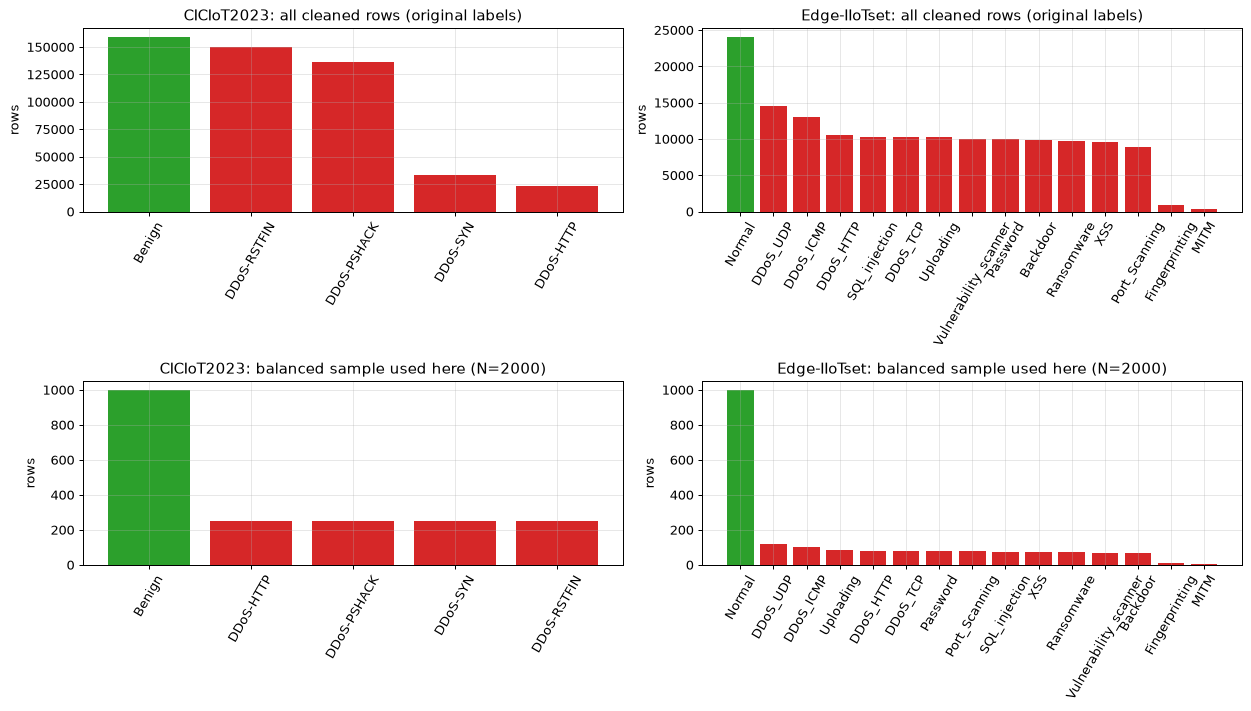

In [8]:
# Class distributions: whole cleaned dataset versus the balanced sample used for training/testing
fig, axes = plt.subplots(2, 2, figsize=(14, 8))
for j, name in enumerate(META):
    vc = META[name]["fam_counts"]
    axes[0, j].bar(vc.index, vc.values, color=["tab:green" if v == "Benign" or v == "Normal" else "tab:red" for v in vc.index])
    axes[0, j].set_title(f"{name}: all cleaned rows (original labels)"); axes[0, j].tick_params(axis="x", rotation=60)
    d = DS[name]
    fam = np.concatenate([d.family["tr"], d.family["va"], d.family["te"]])
    vs = pd.Series(fam).value_counts()
    axes[1, j].bar(vs.index, vs.values, color=["tab:green" if v in ("Benign", "Normal") else "tab:red" for v in vs.index])
    axes[1, j].set_title(f"{name}: balanced sample used here (N={len(fam)})"); axes[1, j].tick_params(axis="x", rotation=60)
    axes[0, j].set_ylabel("rows")
    axes[1, j].set_ylabel("rows")
plt.tight_layout(); plt.show()

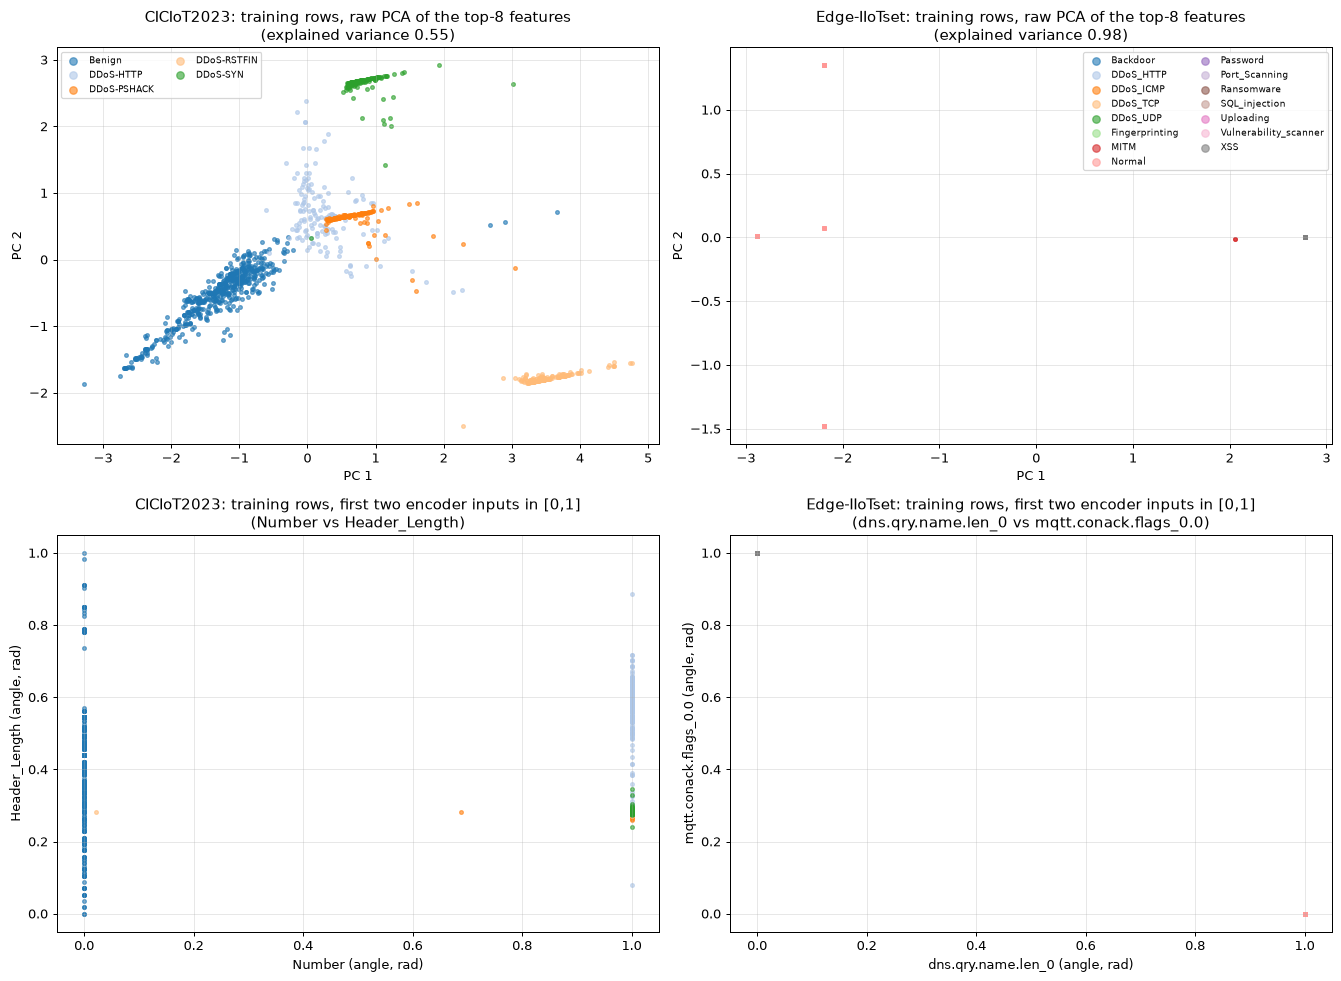

In [9]:
# 2-D scatter of REAL rows coloured by ground-truth family.
# (a) raw PCA of the top-8 selected features (standardised, PCA fitted on the training split)
# (b) the first two selected features after min-max scaling to [0,1]: exactly the rotation angles (radians) that Angle embedding receives
fig, axes = plt.subplots(2, 2, figsize=(15, 11))
palette = plt.cm.tab20(np.linspace(0, 1, 20))
for j, name in enumerate(DS):
    d = DS[name]
    sc01, fnames = d.select(N_QUBITS)
    Xtr_raw = d.raw["tr"][:, d.order[:N_QUBITS]]
    std = StandardScaler().fit(Xtr_raw); pca = PCA(n_components=2, random_state=SEED).fit(std.transform(Xtr_raw))
    Z = pca.transform(std.transform(Xtr_raw))
    fams = sorted(set(d.family["tr"]))
    for i, f in enumerate(fams):
        m = d.family["tr"] == f
        axes[0, j].scatter(Z[m, 0], Z[m, 1], s=9, alpha=0.6, color=palette[i % 20], label=f)
        axes[1, j].scatter(sc01["tr"][m, 0], sc01["tr"][m, 1], s=9, alpha=0.6, color=palette[i % 20], label=f)
    axes[0, j].set_title(f"{name}: training rows, raw PCA of the top-{N_QUBITS} features\n(explained variance {pca.explained_variance_ratio_.sum():.2f})")
    axes[0, j].set_xlabel("PC 1"); axes[0, j].set_ylabel("PC 2"); axes[0, j].legend(fontsize=7, ncol=2, markerscale=2)
    axes[1, j].set_title(f"{name}: training rows, first two encoder inputs in [0,1]\n({fnames[0]} vs {fnames[1]})")
    axes[1, j].set_xlabel(fnames[0] + " (angle, rad)"); axes[1, j].set_ylabel(fnames[1] + " (angle, rad)")
plt.tight_layout(); plt.show()

## Quantum Circuit Architecture

The model of Fig. 1 has three parts: an **encoding circuit** (4 variants), a **trainable entangling circuit** (2 variants), and **one Pauli expectation value per qubit** feeding one sigmoid neuron.
That gives 8 distinct quantum architectures; the code below defines them once in `apply_circuit` and the *same* `QNode` objects are then trained (via `qml.qnn.TorchLayer`) and drawn, so the drawings are of the executed circuits, not illustrations.

Assumptions where the paper gives no circuit details (all taken from the public notebook or marked as choices):
* 8 qubits, 8 features, depth 8 for both the trainable block and the QAOA embedding (`# CHOICE:` from the public code; Fig. 6 states "the number of layers is fixed at 8").
* Amplitude embedding pads the 8 normalised features with zeros to 2^8 = 256 amplitudes, so the data lives in the first 8 basis states; with 2^n features (Fig. 8 sweep) the register is fully used.
* IQP embedding uses PennyLane's `IQPEmbedding` (Hadamards, RZ(x_i), ZZ(x_i x_j) phases, one repetition).
* `QAOAEmbedding` uses `qml.QAOAEmbedding.shape(n_layers, n_wires)` trainable parameters (ZZ interactions and local RY fields) with RX feature layers; its trainable parameters are in addition to the entangling block.
* `StronglyEntanglingLayers` (Rot gates + CNOT ring with range r = 1 on the first layer, increasing range per layer by PennyLane's default) and `BasicEntanglerLayers` (RX + CNOT ring).
* Measurement: Pauli-X on every qubit for Amplitude / Angle, Pauli-Z for IQP / QAOA (public code); the paper text only says "Pauli-Z".
* Angle embedding: the public notebook leaves PennyLane's default rotation (RX); `ROT_DEFAULT = "X"` reproduces that, and Fig. 5 sweeps X / Y / Z.

In [10]:
# Circuit builder shared by training and drawing
ENCODINGS = ["amplitude", "angle", "iqp", "qaoa"]
ENT_LAYERS = ["strong", "basic"]
PRETTY = {"amplitude": "Amplitude", "angle": "Angle", "iqp": "IQP", "qaoa": "QAOA", "strong": "Strongly", "basic": "Basic"}
ROT_DEFAULT = "X"          # CHOICE: PennyLane's AngleEmbedding default, as in the public code
OBS = {"X": qml.PauliX, "Y": qml.PauliY, "Z": qml.PauliZ, "H": qml.Hadamard}
EPS = 1e-6                 # CHOICE: keeps an all-zero row normalisable for Amplitude embedding

def default_meas(enc):
    return "X" if enc in ("amplitude", "angle") else "Z"

def apply_circuit(enc, ent, n, rot, inputs, w_ent, w_enc):
    if enc == "amplitude":
        qml.AmplitudeEmbedding(inputs + EPS, wires=range(n), pad_with=0.0, normalize=True)
    elif enc == "angle":
        qml.AngleEmbedding(inputs, wires=range(n), rotation=rot)
    elif enc == "iqp":
        qml.IQPEmbedding(inputs, wires=range(n))
    elif enc == "qaoa":
        qml.QAOAEmbedding(inputs, w_enc, wires=range(n))
    if ent == "strong":
        qml.StronglyEntanglingLayers(w_ent, wires=range(n))
    else:
        qml.BasicEntanglerLayers(w_ent, wires=range(n))

def weight_shapes(enc, ent, n, L):
    sh = {"w_ent": (L, n, 3) if ent == "strong" else (L, n)}
    if enc == "qaoa":
        sh["w_enc"] = tuple(qml.QAOAEmbedding.shape(n_layers=L, n_wires=n))
    return sh

def make_qnode(enc, ent, n, L, rot=ROT_DEFAULT, meas=None, output="expval"):
    meas = meas or default_meas(enc)
    dev = qml.device("default.qubit", wires=n)
    def ret():
        return [qml.expval(OBS[meas](i)) for i in range(n)] if output == "expval" else qml.state()
    if enc == "qaoa":
        def f(inputs, w_ent, w_enc):
            apply_circuit(enc, ent, n, rot, inputs, w_ent, w_enc); return ret()
    else:
        def f(inputs, w_ent):
            apply_circuit(enc, ent, n, rot, inputs, w_ent, None); return ret()
    return qml.QNode(f, dev, interface="torch", diff_method="backprop")

class HybridNet(nn.Module):
    # encoding + trainable circuit + Pauli expectations -> Dense(1) -> sigmoid (Fig. 1)
    def __init__(self, enc, ent, n, L, rot=ROT_DEFAULT, meas=None):
        super().__init__()
        self.qnode = make_qnode(enc, ent, n, L, rot, meas)
        init = lambda t: nn.init.uniform_(t, -np.pi, np.pi)          # paper: weights uniform in [-pi, pi]
        self.q = qml.qnn.TorchLayer(self.qnode, weight_shapes(enc, ent, n, L), init_method=init)
        self.head = nn.Linear(n, 1)
    def forward(self, x):
        return self.head(self.q(x).float()).squeeze(-1)             # logit; sigmoid is inside BCEWithLogits / prediction

def circuit_report(enc, ent, n=N_QUBITS, L=N_LAYERS, rot=ROT_DEFAULT, meas=None):
    set_all_seeds(SEED)
    net = HybridNet(enc, ent, n, L, rot, meas)
    x = torch.rand(n, dtype=torch.float32)
    weights = [p.detach() for p in net.q.qnode_weights.values()]
    sp = qml.specs(net.qnode, level="device")(x, *weights)
    res = sp.resources if hasattr(sp, "resources") else sp["resources"]
    depth = res.depth if hasattr(res, "depth") else res["depth"]
    qparams = int(sum(w.numel() for w in weights))
    return net, x, weights, depth, qparams

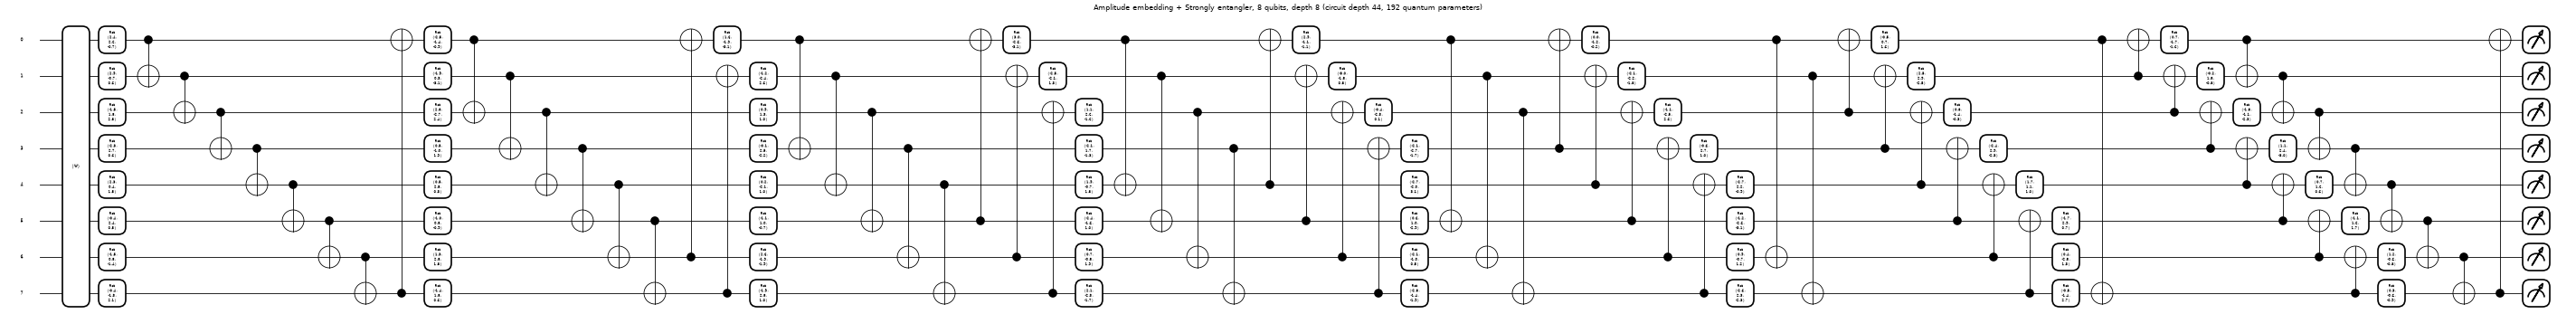

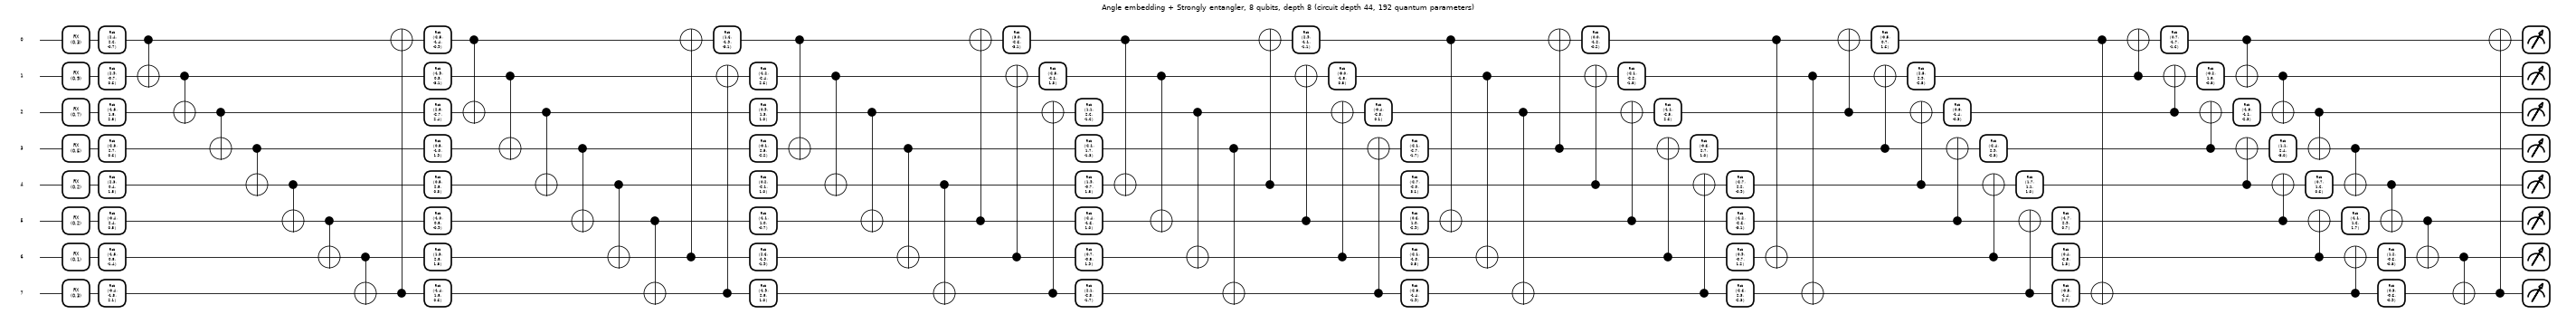

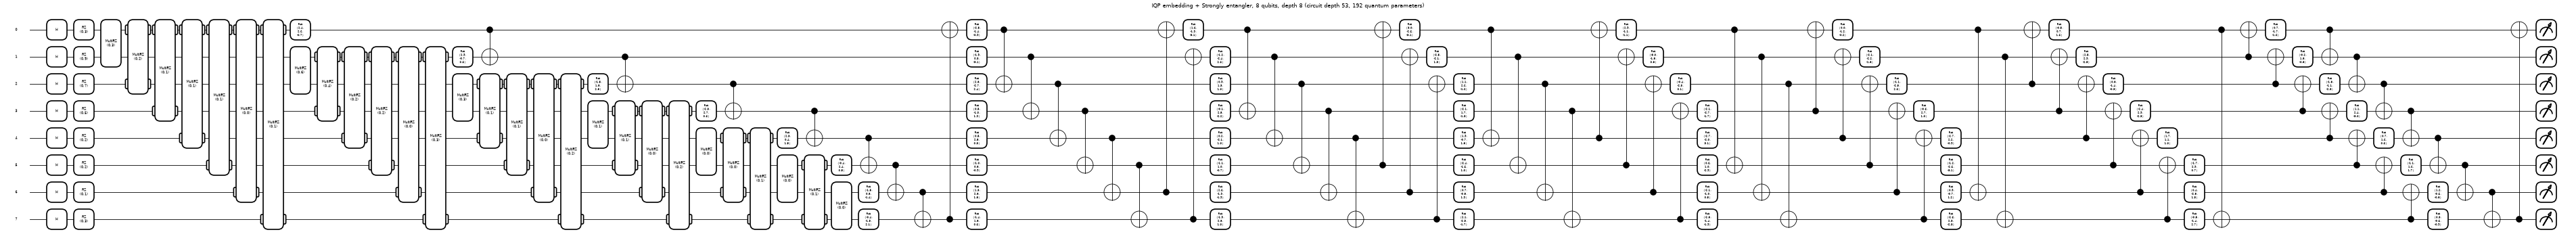

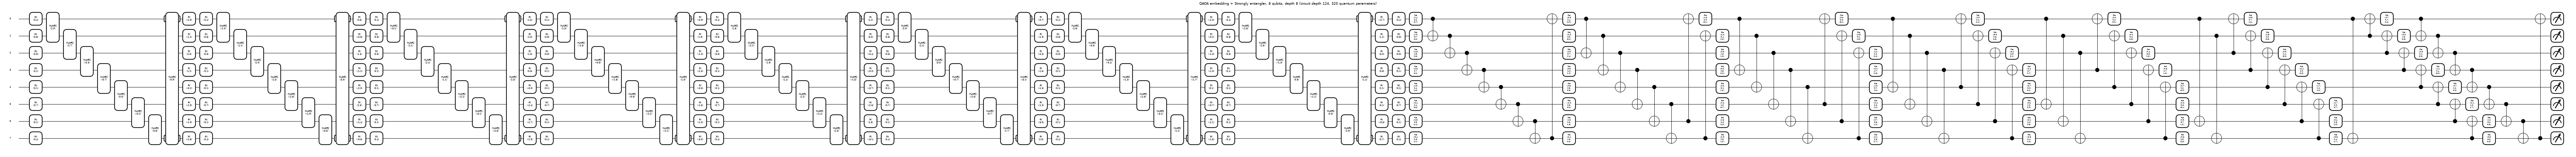

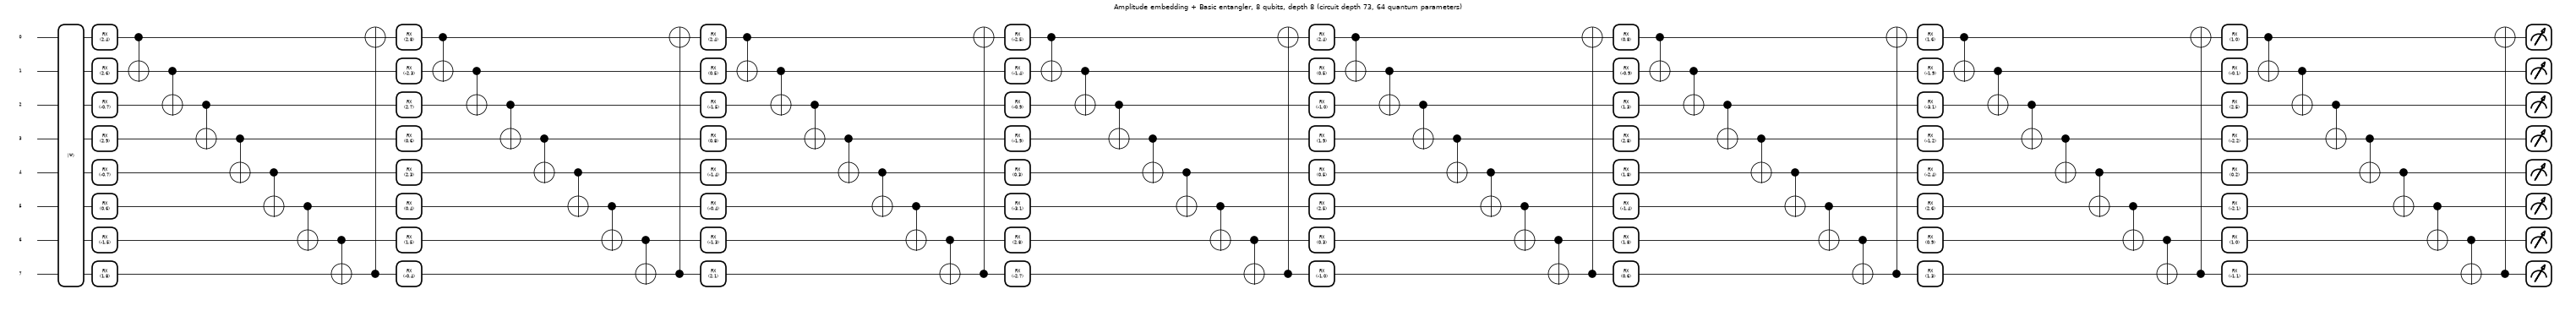

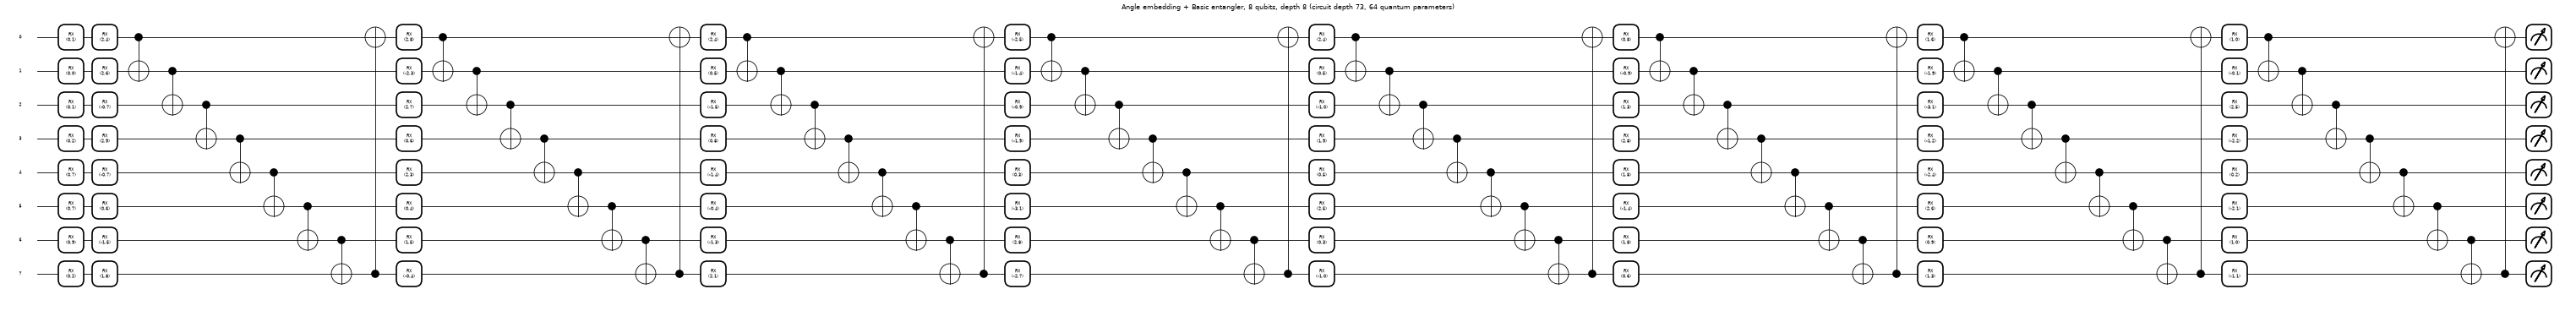

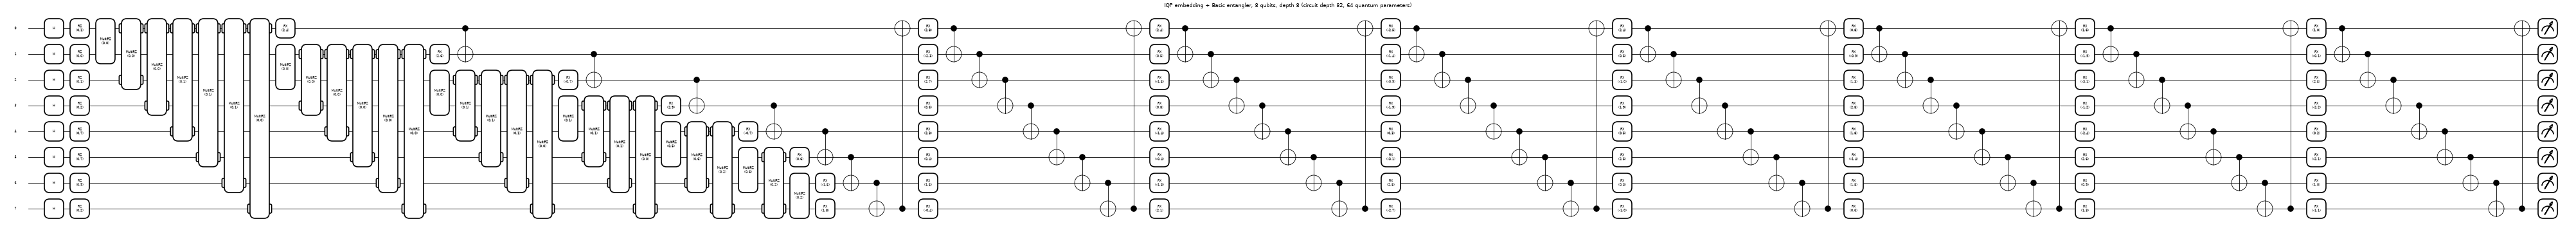

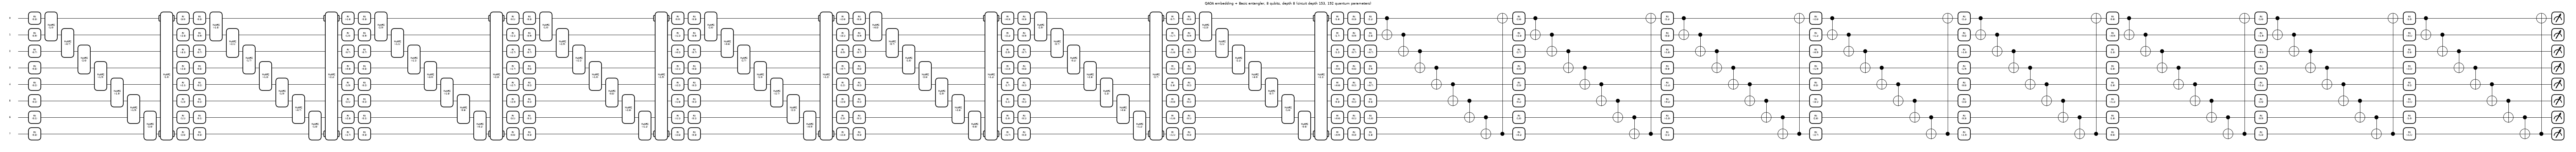

 encoding          trainable block  qubits  circuit depth  quantum params  total params (+Dense) measurement
Amplitude StronglyEntanglingLayers       8             44             192                    201     Pauli-X
    Angle StronglyEntanglingLayers       8             44             192                    201     Pauli-X
      IQP StronglyEntanglingLayers       8             53             192                    201     Pauli-Z
     QAOA StronglyEntanglingLayers       8            124             320                    329     Pauli-Z
Amplitude     BasicEntanglerLayers       8             73              64                     73     Pauli-X
    Angle     BasicEntanglerLayers       8             73              64                     73     Pauli-X
      IQP     BasicEntanglerLayers       8             82              64                     73     Pauli-Z
     QAOA     BasicEntanglerLayers       8            153             192                    201     Pauli-Z


In [11]:
# Draw the 8 executed architectures (n = N_QUBITS qubits, depth N_LAYERS), full gate-level decomposition + counts
rows = []
for ent in ENT_LAYERS:
    for enc in ENCODINGS:
        net, x, weights, depth, qparams = circuit_report(enc, ent)
        total_params = qparams + sum(p.numel() for p in net.head.parameters())
        rows.append({"encoding": PRETTY[enc], "trainable block": PRETTY[ent] + "EntanglingLayers" if ent == "strong" else "BasicEntanglerLayers",
                     "qubits": N_QUBITS, "circuit depth": depth, "quantum params": qparams, "total params (+Dense)": total_params,
                     "measurement": "Pauli-" + default_meas(enc)})
        fig, ax = qml.draw_mpl(net.qnode, level="device", decimals=1, fontsize=9)(x, *weights)
        fig.suptitle(f"{PRETTY[enc]} embedding + {PRETTY[ent]} entangler, {N_QUBITS} qubits, depth {N_LAYERS} "
                     f"(circuit depth {depth}, {qparams} quantum parameters)", y=1.0, fontsize=14)
        fig.set_dpi(40); plt.show()
print(pd.DataFrame(rows).to_string(index=False))

OK: drawn QNode == the circuit inside the trained layer (max abs diff = 7.03e-09)


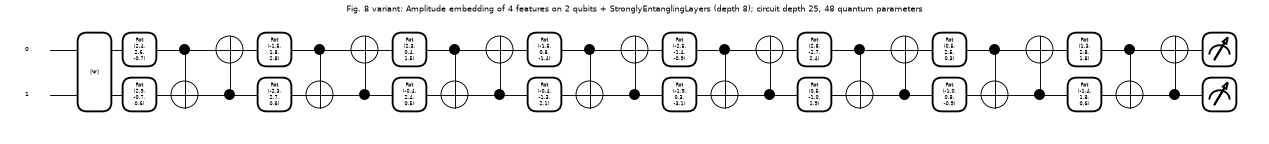

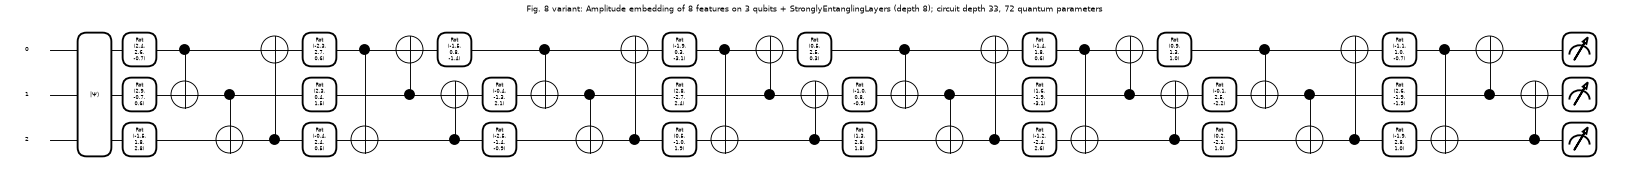

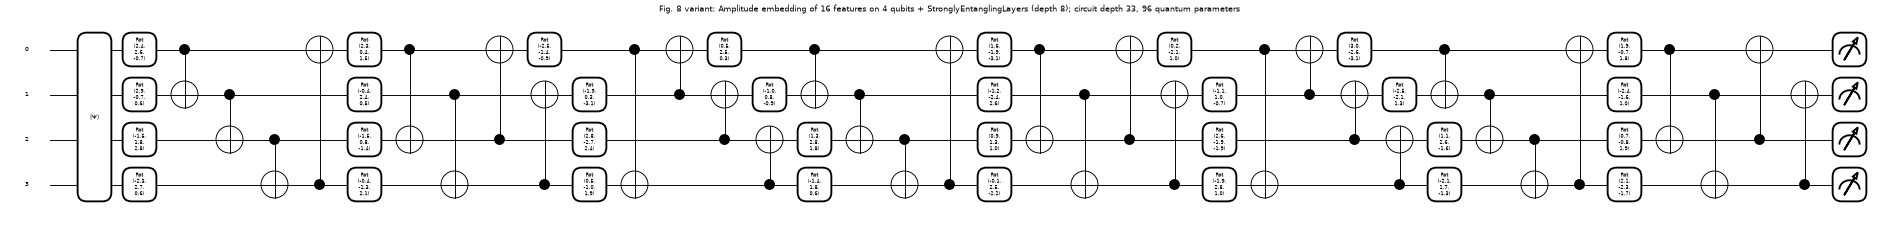

In [12]:
# Equivalence check: the TorchLayer output equals a direct execution of the drawn QNode with the same weights
net, x, weights, depth, qparams = circuit_report("qaoa", "strong")
direct = torch.stack(net.qnode(x, *weights)).detach().double()
layer_out = net.q(x.unsqueeze(0)).detach().double().squeeze(0)
assert torch.allclose(direct, layer_out, atol=1e-6), "drawn circuit differs from the trained layer"
print("OK: drawn QNode == the circuit inside the trained layer (max abs diff = %.2e)" % (direct - layer_out).abs().max())

# the 2/3/4-qubit Amplitude circuit of Fig. 8 uses 2^n features, so the register is fully used (drawn at the sizes that are trained)
for nq in FIG8_QUBITS:
    net_a, xa, wa, da, qa = circuit_report("amplitude", "strong", n=nq, L=N_LAYERS)
    xa = torch.rand(2 ** nq)
    fig, ax = qml.draw_mpl(net_a.qnode, level="device", decimals=1, fontsize=9)(xa, *wa)
    fig.suptitle(f"Fig. 8 variant: Amplitude embedding of {2**nq} features on {nq} qubits + StronglyEntanglingLayers (depth {N_LAYERS}); "
                 f"circuit depth {da}, {qa} quantum parameters", y=1.0, fontsize=12)
    fig.set_dpi(45); plt.show()

## 4. Training machinery (Algorithm 1, Module 02 and 03)

`train_eval` builds the hybrid network, trains it with Adam on binary cross-entropy (mini-batches, shuffled with a seeded generator), records the validation accuracy after every epoch (for the Fig. 6 style curves), and finally reports accuracy, precision, recall, F1 and the confusion matrix on the **test** split, with attack as the positive class. Nothing is tuned on the test split.

In [13]:
def predict(net, X, bs=500):
    net.eval(); out = []
    with torch.no_grad():
        for i in range(0, len(X), bs):
            out.append(torch.sigmoid(net(torch.tensor(X[i:i + bs], dtype=torch.float32))).numpy())
    return np.concatenate(out)

def metrics_of(y, p):
    yh = (p > 0.5).astype(int)
    return dict(acc=accuracy_score(y, yh), prec=precision_score(y, yh, zero_division=0), rec=recall_score(y, yh, zero_division=0),
                f1=f1_score(y, yh, zero_division=0), cm=confusion_matrix(y, yh, labels=[0, 1]))

def train_eval(data, enc, ent, n, L, epochs, batch, lr=LR, seed=SEED, rot=ROT_DEFAULT, meas=None, verbose=False):
    # data: dict from Prepared.select with keys tr/va/te plus y from the parent; passed as (X, y) dicts
    X, y = data
    set_all_seeds(seed)
    net = HybridNet(enc, ent, n, L, rot, meas)
    opt = torch.optim.Adam(net.parameters(), lr=lr)
    lossf = nn.BCEWithLogitsLoss()
    r = np.random.default_rng(seed)
    hist = []; t0 = time.time()
    Xt = torch.tensor(X["tr"], dtype=torch.float32); yt = torch.tensor(y["tr"], dtype=torch.float32)
    for ep in range(epochs):
        net.train(); perm = r.permutation(len(Xt)); tot = 0.0; nb = 0
        for i in range(0, len(perm), batch):
            b = perm[i:i + batch]
            opt.zero_grad(); loss = lossf(net(Xt[b]), yt[b]); loss.backward(); opt.step()
            tot += loss.item(); nb += 1
        va = accuracy_score(y["va"], (predict(net, X["va"]) > 0.5).astype(int))
        hist.append(dict(epoch=ep + 1, loss=tot / nb, val_acc=va))
        if verbose: print(f"   epoch {ep+1:2d}  loss {tot/nb:.4f}  val acc {va:.3f}")
    fit_time = time.time() - t0
    t1 = time.time(); p = predict(net, X["te"]); m = metrics_of(y["te"], p); m["pred_time"] = time.time() - t1
    m.update(fit_time=fit_time, hist=pd.DataFrame(hist), n_params=sum(q.numel() for q in net.parameters()))
    return m

def get_data(name, k):
    d = DS[name]; X, feats = d.select(k)
    return (X, d.y), feats

# quick smoke test on the smallest configuration
(Xs, ys), fn = get_data("CICIoT2023", 4)
t = train_eval((Xs, ys), "angle", "basic", 4, 1, 1, BATCH_MAIN)
print("smoke test OK:", {k: (round(v, 3) if isinstance(v, float) else v) for k, v in t.items() if k in ("acc", "fit_time", "n_params")})

smoke test OK: {'acc': 0.5, 'fit_time': 0.58, 'n_params': 9}


## 5. Classical baselines on exactly the same inputs

Three classical models see the same 8 scaled features and the same train/test split as the quantum models: a Random Forest, an RBF SVM and a logistic regression. A small classical MLP (k-k-1, tanh) plays the role of the paper's "classical part only" and a Random Forest on **all** features shows the ceiling of the data.

In [14]:
def classical_block(name):
    d = DS[name]; (X, y), fn = get_data(name, N_QUBITS)
    Xtr = np.vstack([X["tr"], X["va"]]); ytr = np.concatenate([y["tr"], y["va"]])
    models = {
        "RandomForest (top-k features)": RandomForestClassifier(n_estimators=200, random_state=SEED, n_jobs=2),
        "SVC rbf C=1 (top-k features)": SVC(kernel="rbf", C=1.0, random_state=SEED),
        "LogisticRegression (top-k features)": LogisticRegression(max_iter=1000, random_state=SEED),
        "MLP k-k-1 tanh (top-k features)": MLPClassifier(hidden_layer_sizes=(N_QUBITS,), activation="tanh", max_iter=500, random_state=SEED),
    }
    out = []
    for nm, m in models.items():
        t0 = time.time(); m.fit(Xtr, ytr); yh = m.predict(X["te"])
        out.append(dict(dataset=name, model=nm, acc=accuracy_score(y["te"], yh), prec=precision_score(y["te"], yh, zero_division=0),
                        rec=recall_score(y["te"], yh, zero_division=0), f1=f1_score(y["te"], yh, zero_division=0), seconds=time.time() - t0))
    # all-feature Random Forest (scaler fitted on training only)
    sc = MinMaxScaler().fit(np.vstack([d.raw["tr"], d.raw["va"]]))
    rf = RandomForestClassifier(n_estimators=200, random_state=SEED, n_jobs=2).fit(sc.transform(np.vstack([d.raw["tr"], d.raw["va"]])), ytr)
    yh = rf.predict(np.clip(sc.transform(d.raw["te"]), 0, 1))
    out.append(dict(dataset=name, model=f"RandomForest (all {len(d.features)} features)", acc=accuracy_score(y["te"], yh),
                    prec=precision_score(y["te"], yh), rec=recall_score(y["te"], yh), f1=f1_score(y["te"], yh), seconds=np.nan))
    return out

BASE = pd.DataFrame(sum([classical_block(n) for n in DS], []))
print(BASE.round(4).to_string(index=False))

     dataset                               model  acc  prec  rec  f1  seconds
  CICIoT2023       RandomForest (top-k features)  1.0   1.0  1.0 1.0   1.1520
  CICIoT2023        SVC rbf C=1 (top-k features)  1.0   1.0  1.0 1.0   0.0442
  CICIoT2023 LogisticRegression (top-k features)  1.0   1.0  1.0 1.0   0.0450
  CICIoT2023     MLP k-k-1 tanh (top-k features)  1.0   1.0  1.0 1.0   2.2674
  CICIoT2023      RandomForest (all 39 features)  1.0   1.0  1.0 1.0      NaN
Edge-IIoTset       RandomForest (top-k features)  1.0   1.0  1.0 1.0   1.1340
Edge-IIoTset        SVC rbf C=1 (top-k features)  1.0   1.0  1.0 1.0   0.0285
Edge-IIoTset LogisticRegression (top-k features)  1.0   1.0  1.0 1.0   0.0524
Edge-IIoTset     MLP k-k-1 tanh (top-k features)  1.0   1.0  1.0 1.0   1.2406
Edge-IIoTset      RandomForest (all 74 features)  1.0   1.0  1.0 1.0      NaN


## 6. Experiment 1 - Table 4 and Figs. 6 and 10: four encodings x two entanglers x two datasets

Settings of the public code (full run): 8 qubits, 8 features, depth 8, Adam, binary cross-entropy, `EPOCHS_MAIN` epochs, batch 100. Every cell of the grid is one training run with `SEED`.
The validation accuracy after each epoch gives the Fig. 6 style curves; the test metrics give the Table 4 style table.

In [15]:
T4 = []            # rows of the Table 4 style table
HIST = {}          # (dataset, enc, ent) -> per-epoch history
CMS = {}
t_all = time.time()
for name in DS:
    data, fn = get_data(name, N_QUBITS)
    for ent in ENT_LAYERS:
        for enc in ENCODINGS:
            r = train_eval(data, enc, ent, N_QUBITS, N_LAYERS, EPOCHS_MAIN, BATCH_MAIN)
            T4.append(dict(dataset=name, encoding=PRETTY[enc], entangler=PRETTY[ent], acc=r["acc"], prec=r["prec"], rec=r["rec"], f1=r["f1"],
                           fit_s=r["fit_time"], params=r["n_params"]))
            HIST[(name, enc, ent)] = r["hist"]; CMS[(name, enc, ent)] = r["cm"]
            print(f"{name:13s} {PRETTY[enc]:9s} {PRETTY[ent]:8s} acc {r['acc']:.3f}  prec {r['prec']:.3f}  rec {r['rec']:.3f}  f1 {r['f1']:.3f}  ({r['fit_time']:.0f} s)")
T4 = pd.DataFrame(T4)
print(f"\nExperiment 1 took {(time.time()-t_all)/60:.1f} min")

CICIoT2023    Amplitude Strongly acc 1.000  prec 1.000  rec 1.000  f1 1.000  (116 s)


CICIoT2023    Angle     Strongly acc 1.000  prec 1.000  rec 1.000  f1 1.000  (124 s)


CICIoT2023    IQP       Strongly acc 1.000  prec 1.000  rec 1.000  f1 1.000  (138 s)


CICIoT2023    QAOA      Strongly acc 1.000  prec 1.000  rec 1.000  f1 1.000  (276 s)


CICIoT2023    Amplitude Basic    acc 0.805  prec 0.769  rec 0.870  f1 0.817  (61 s)


...

Edge-IIoTset  QAOA      Strongly acc 1.000  prec 1.000  rec 1.000  f1 1.000  (987 s)


Edge-IIoTset  Amplitude Basic    acc 0.547  prec 0.525  rec 1.000  f1 0.688  (62 s)


Edge-IIoTset  Angle     Basic    acc 0.500  prec 0.000  rec 0.000  f1 0.000  (83 s)


Edge-IIoTset  IQP       Basic    acc 1.000  prec 1.000  rec 1.000  f1 1.000  (77 s)


Edge-IIoTset  QAOA      Basic    acc 1.000  prec 1.000  rec 1.000  f1 1.000  (353 s)

Experiment 1 took 52.9 min


In [16]:
# Table 4 style table (test split, attack = positive class)
show = T4.copy()
for c in ("acc", "prec", "rec", "f1"): show[c] = show[c].round(3)
print(show.drop(columns=["params"]).to_string(index=False))
print()
print("Pivot of test accuracy:")
print(T4.pivot_table(index=["encoding"], columns=["dataset", "entangler"], values="acc").round(3).to_string())

     dataset  encoding entangler   acc  prec  rec    f1      fit_s
  CICIoT2023 Amplitude  Strongly 1.000 1.000 1.00 1.000 116.324920
  CICIoT2023     Angle  Strongly 1.000 1.000 1.00 1.000 124.054097
  CICIoT2023       IQP  Strongly 1.000 1.000 1.00 1.000 137.563470
  CICIoT2023      QAOA  Strongly 1.000 1.000 1.00 1.000 276.382212
  CICIoT2023 Amplitude     Basic 0.805 0.769 0.87 0.817  61.327695
  CICIoT2023     Angle     Basic 0.500 0.000 0.00 0.000  71.118831
  CICIoT2023       IQP     Basic 1.000 1.000 1.00 1.000  82.796915
  CICIoT2023      QAOA     Basic 1.000 1.000 1.00 1.000 255.999619
Edge-IIoTset Amplitude  Strongly 1.000 1.000 1.00 1.000 118.913080
Edge-IIoTset     Angle  Strongly 1.000 1.000 1.00 1.000 171.587943
Edge-IIoTset       IQP  Strongly 1.000 1.000 1.00 1.000 122.521265
Edge-IIoTset      QAOA  Strongly 1.000 1.000 1.00 1.000 986.916395
Edge-IIoTset Amplitude     Basic 0.547 0.525 1.00 0.688  62.075955
Edge-IIoTset     Angle     Basic 0.500 0.000 0.00 0.000  83.14

dataset   CICIoT2023          Edge-IIoTset         
entangler      Basic Strongly        Basic Strongly
encoding                                           
Amplitude      0.805      1.0        0.547      1.0
Angle          0.500      1.0        0.500      1.0
IQP            1.000      1.0        1.000      1.0
QAOA           1.000      1.0        1.000      1.0


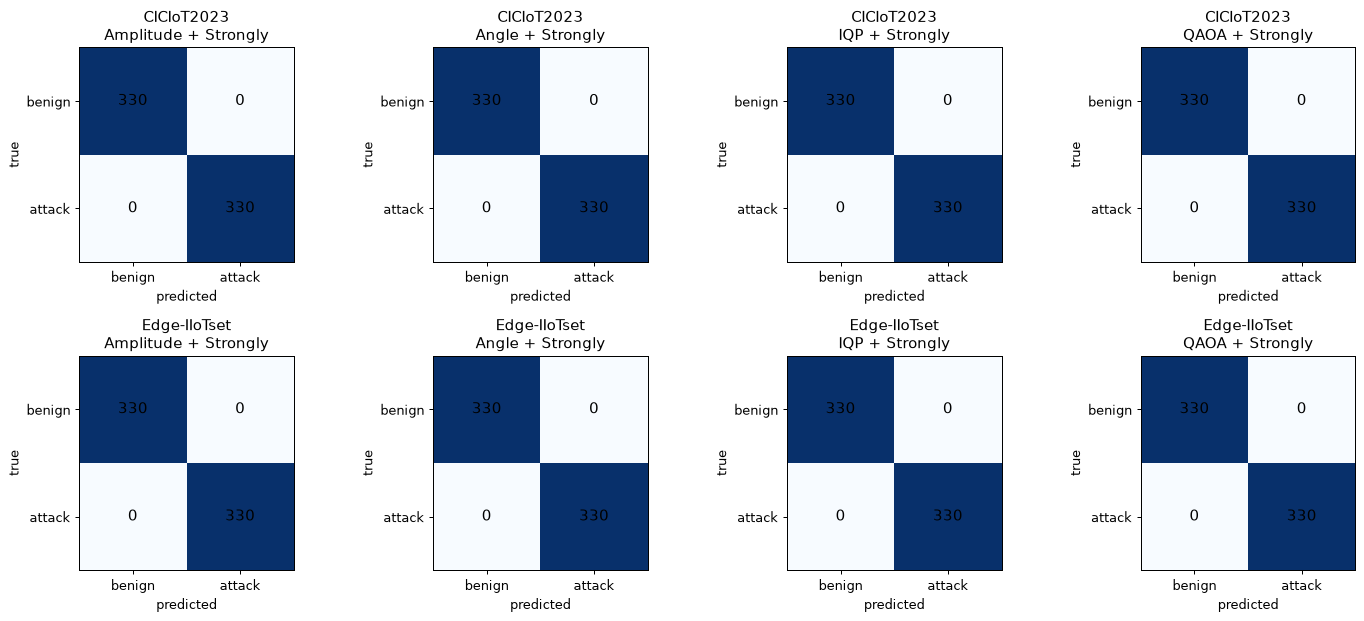

In [17]:
# Confusion matrices (attack = positive class) for the Strongly entangling circuit
fig, axes = plt.subplots(2, 4, figsize=(16, 7))
for i, name in enumerate(DS):
    for j, enc in enumerate(ENCODINGS):
        cm = CMS[(name, enc, "strong")]; ax = axes[i, j]
        ax.imshow(cm, cmap="Blues"); ax.grid(False)
        for a in range(2):
            for b in range(2): ax.text(b, a, cm[a, b], ha="center", va="center", color="black", fontsize=12)
        ax.set_xticks([0, 1]); ax.set_xticklabels(["benign", "attack"]); ax.set_yticks([0, 1]); ax.set_yticklabels(["benign", "attack"])
        ax.set_title(f"{name}\n{PRETTY[enc]} + Strongly"); ax.set_xlabel("predicted"); ax.set_ylabel("true")
plt.tight_layout(); plt.show()

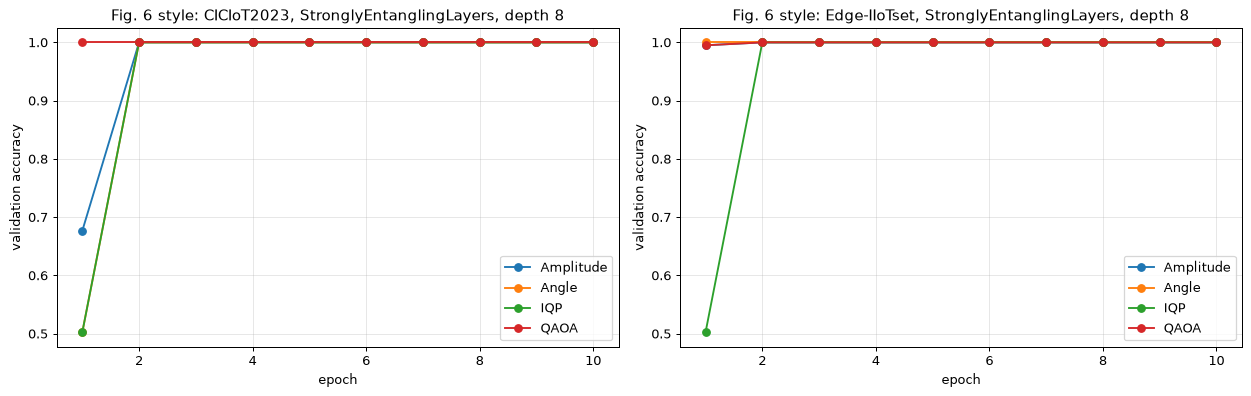

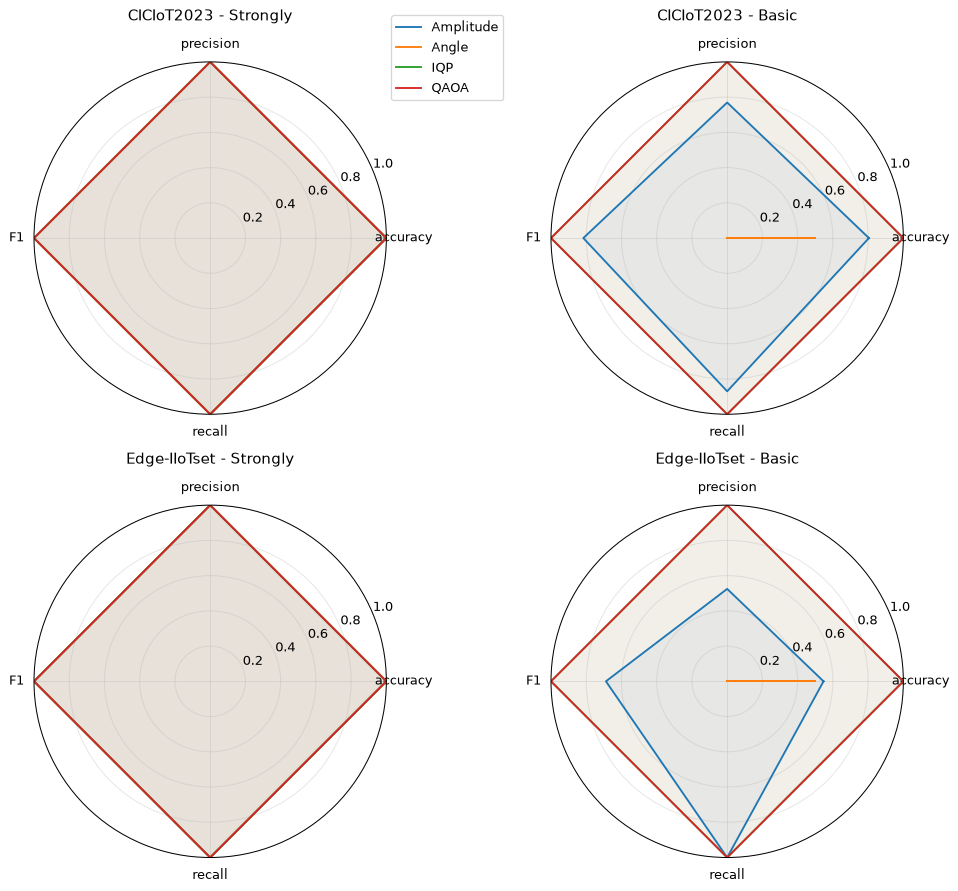

In [18]:
# Fig. 6 style: validation accuracy over epochs (CICIoT2023, depth 8), plus the same for Edge-IIoTset
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
for ax, name in zip(axes, DS):
    for enc in ENCODINGS:
        h = HIST[(name, enc, "strong")]; ax.plot(h["epoch"], h["val_acc"], marker="o", label=PRETTY[enc])
    ax.set_title(f"Fig. 6 style: {name}, StronglyEntanglingLayers, depth {N_LAYERS}"); ax.set_xlabel("epoch"); ax.set_ylabel("validation accuracy"); ax.legend()
plt.tight_layout(); plt.show()

# Fig. 10 style radar charts of accuracy / precision / F1 / recall
fig, axes = plt.subplots(2, 2, figsize=(11, 10), subplot_kw=dict(polar=True))
labels = ["accuracy", "precision", "F1", "recall"]; cols = ["acc", "prec", "f1", "rec"]
ang = np.linspace(0, 2 * np.pi, 4, endpoint=False).tolist(); ang += ang[:1]
for i, name in enumerate(DS):
    for j, ent in enumerate(ENT_LAYERS):
        ax = axes[i, j]; ax.grid(True)
        for enc in ENCODINGS:
            row = T4[(T4.dataset == name) & (T4.encoding == PRETTY[enc]) & (T4.entangler == PRETTY[ent])].iloc[0]
            v = [row[c] for c in cols] + [row[cols[0]]]; ax.plot(ang, v, label=PRETTY[enc]); ax.fill(ang, v, alpha=0.05)
        ax.set_xticks(ang[:-1]); ax.set_xticklabels(labels); ax.set_ylim(0, 1); ax.set_title(f"{name} - {PRETTY[ent]}", pad=14)
        if i == 0 and j == 0: ax.legend(loc="upper right", bbox_to_anchor=(1.35, 1.15))
plt.tight_layout(); plt.show()

## 7. Experiment 2 - Fig. 7: accuracy versus circuit depth

Depth of the trainable block (and of the QAOA embedding) is varied over `LAYER_GRID` for the four encodings and both entanglers on CICIoT2023 (`EPOCHS_SMALL` epochs, batch 50, Adam as in the figure caption). The paper does not give the qubit count of this sweep; we use **4 qubits / 4 features** to keep the 40-run sweep affordable.

Experiment 2 took 11.6 min


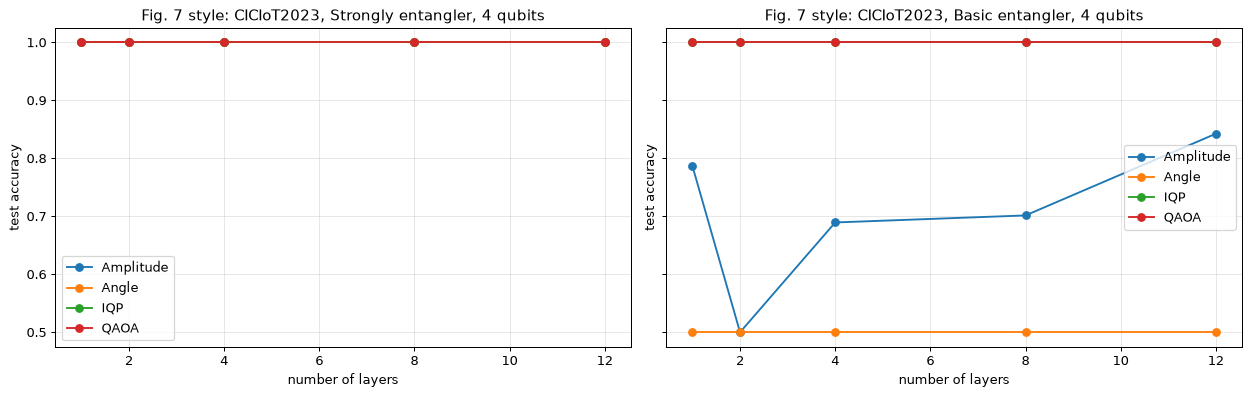

layers                  1    2      4      8      12
entangler encoding                                  
Basic     Amplitude  0.786  0.5  0.689  0.702  0.842
          Angle      0.500  0.5  0.500  0.500  0.500
          IQP        1.000  1.0  1.000  1.000  1.000
          QAOA       1.000  1.0  1.000  1.000  1.000
Strongly  Amplitude  1.000  1.0  1.000  1.000  1.000
          Angle      1.000  1.0  1.000  1.000  1.000
          IQP        1.000  1.0  1.000  1.000  1.000
          QAOA       1.000  1.0  1.000  1.000  1.000


In [19]:
t_all = time.time(); FIG7 = []
data4, _ = get_data("CICIoT2023", 4)
for ent in ENT_LAYERS:
    for enc in ENCODINGS:
        for L in LAYER_GRID:
            r = train_eval(data4, enc, ent, 4, L, EPOCHS_SMALL, BATCH_SMALL)
            FIG7.append(dict(encoding=PRETTY[enc], entangler=PRETTY[ent], layers=L, acc=r["acc"], f1=r["f1"], fit_s=r["fit_time"]))
FIG7 = pd.DataFrame(FIG7)
print(f"Experiment 2 took {(time.time()-t_all)/60:.1f} min")
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5), sharey=True)
for ax, ent in zip(axes, ENT_LAYERS):
    for enc in ENCODINGS:
        s = FIG7[(FIG7.encoding == PRETTY[enc]) & (FIG7.entangler == PRETTY[ent])]; ax.plot(s["layers"], s["acc"], marker="o", label=PRETTY[enc])
    ax.set_title(f"Fig. 7 style: CICIoT2023, {PRETTY[ent]} entangler, 4 qubits"); ax.set_xlabel("number of layers"); ax.set_ylabel("test accuracy"); ax.legend()
plt.tight_layout(); plt.show()
print(FIG7.pivot_table(index=["entangler", "encoding"], columns="layers", values="acc").round(3).to_string())

## 8. Experiment 3 - Fig. 8: accuracy versus number of qubits / features

Amplitude embedding with StronglyEntanglingLayers (Adam, binary cross-entropy, `EPOCHS_FIG8` epochs, batch 50): 2, 3 and 4 qubits carry 4, 8 and 16 features, since n qubits hold 2^n amplitudes. The paper reports 85 % (2 qubits) and 89 % (4 qubits) for CICIoT2023, and 70 % and 73 % for Edge-IIoTset.

CICIoT2023    2 qubits /  4 features: 1.000, 1.000


CICIoT2023    3 qubits /  8 features: 1.000, 1.000


CICIoT2023    4 qubits / 16 features: 1.000, 1.000


Edge-IIoTset  2 qubits /  4 features: 0.998, 0.998


Edge-IIoTset  3 qubits /  8 features: 1.000, 1.000


Edge-IIoTset  4 qubits / 16 features: 1.000, 1.000

Experiment 3 took 7.4 min
     dataset  qubits  features  acc_mean  acc_std
  CICIoT2023       2         4     1.000      0.0
  CICIoT2023       3         8     1.000      0.0
  CICIoT2023       4        16     1.000      0.0
Edge-IIoTset       2         4     0.998      0.0
Edge-IIoTset       3         8     1.000      0.0
Edge-IIoTset       4        16     1.000      0.0


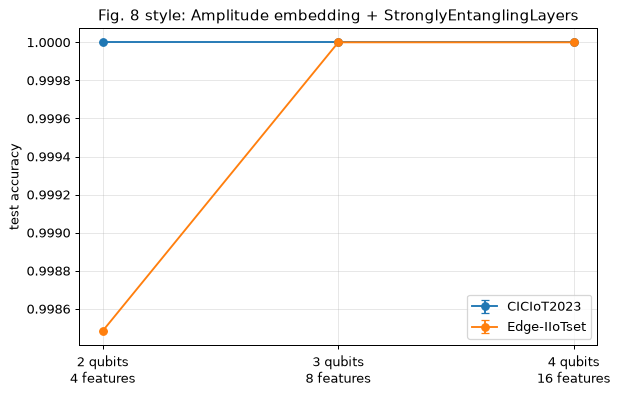

In [20]:
t_all = time.time(); FIG8 = []
for name in DS:
    for nq in FIG8_QUBITS:
        data_k, _ = get_data(name, 2 ** nq)
        for sd in FIG8_SEEDS:
            r = train_eval(data_k, "amplitude", "strong", nq, N_LAYERS, EPOCHS_FIG8, BATCH_SMALL, seed=sd)
            FIG8.append(dict(dataset=name, qubits=nq, features=2 ** nq, seed=sd, acc=r["acc"], f1=r["f1"]))
        print(f"{name:13s} {nq} qubits / {2**nq:2d} features: " + ", ".join(f"{a:.3f}" for a in [x['acc'] for x in FIG8 if x['dataset']==name and x['qubits']==nq]))
FIG8 = pd.DataFrame(FIG8)
F8 = FIG8.groupby(["dataset", "qubits", "features"]).agg(acc_mean=("acc", "mean"), acc_std=("acc", "std")).reset_index()
print(f"\nExperiment 3 took {(time.time()-t_all)/60:.1f} min")
print(F8.round(3).to_string(index=False))
fig, ax = plt.subplots(figsize=(7, 4.5))
for name in DS:
    s = F8[F8.dataset == name]; ax.errorbar(s["qubits"], s["acc_mean"], yerr=s["acc_std"].fillna(0), marker="o", capsize=3, label=name)
ax.set_xticks(FIG8_QUBITS); ax.set_xticklabels([f"{q} qubits\n{2**q} features" for q in FIG8_QUBITS])
ax.set_ylabel("test accuracy"); ax.set_title("Fig. 8 style: Amplitude embedding + StronglyEntanglingLayers"); ax.legend(); plt.tight_layout(); plt.show()

## 9. Experiment 4 - Fig. 5: rotation axis x measurement basis (Angle embedding)

Angle embedding on CICIoT2023 with StronglyEntanglingLayers, `EPOCHS_SMALL` epochs, batch 50. The embedding rotation (X, Y or Z) is crossed with the measured observable (Pauli-X, Pauli-Y, Pauli-Z, Hadamard). The paper reports that Y rotations with Pauli-X or Pauli-Y measurement reach 93.08 % validation accuracy and that Z rotations measured in X stall near 50 %.
A **Z rotation of the |0> state only changes a global phase**, so it should carry no information at all; the run lets you see whether the model indeed ends at chance level.

Experiment 4 took 38.9 min
Validation accuracy (what Fig. 5 plots):
measurement  Hadamard  Pauli-X  Pauli-Y  Pauli-Z
rotation                                        
X               1.000    1.000    1.000    1.000
Y               1.000    1.000    1.000    1.000
Z               0.498    0.498    0.498    0.498

Test accuracy:
measurement  Hadamard  Pauli-X  Pauli-Y  Pauli-Z
rotation                                        
X                 1.0      1.0      1.0      1.0
Y                 1.0      1.0      1.0      1.0
Z                 0.5      0.5      0.5      0.5


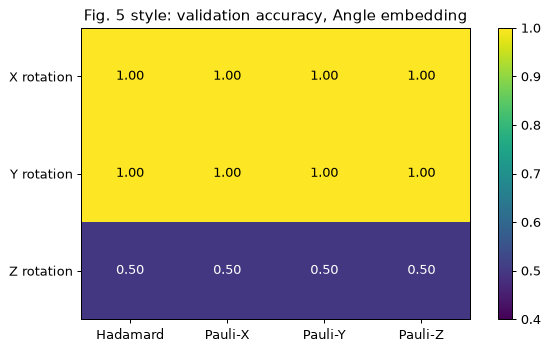

In [21]:
t_all = time.time(); FIG5 = []
data8, _ = get_data("CICIoT2023", N_QUBITS)
for rot in ["X", "Y", "Z"]:
    for meas in FIG5_MEAS:
        r = train_eval(data8, "angle", "strong", N_QUBITS, N_LAYERS, EPOCHS_SMALL, BATCH_SMALL, rot=rot, meas=meas)
        FIG5.append(dict(rotation=rot, measurement={"H": "Hadamard"}.get(meas, "Pauli-" + meas), acc=r["acc"], val_acc=r["hist"]["val_acc"].iloc[-1], f1=r["f1"]))
FIG5 = pd.DataFrame(FIG5)
print(f"Experiment 4 took {(time.time()-t_all)/60:.1f} min")
piv = FIG5.pivot(index="rotation", columns="measurement", values="val_acc")
pivt = FIG5.pivot(index="rotation", columns="measurement", values="acc")
print("Validation accuracy (what Fig. 5 plots):"); print(piv.round(3).to_string())
print("\nTest accuracy:"); print(pivt.round(3).to_string())
fig, ax = plt.subplots(figsize=(7, 4))
im = ax.imshow(piv.values, vmin=0.4, vmax=1.0, cmap="viridis"); ax.grid(False)
ax.set_xticks(range(piv.shape[1])); ax.set_xticklabels(piv.columns); ax.set_yticks(range(3)); ax.set_yticklabels(["X rotation", "Y rotation", "Z rotation"])
for a in range(3):
    for b in range(piv.shape[1]): ax.text(b, a, f"{piv.values[a, b]:.2f}", ha="center", va="center", color="white" if piv.values[a, b] < 0.8 else "black")
ax.set_title("Fig. 5 style: validation accuracy, Angle embedding"); plt.colorbar(im); plt.tight_layout(); plt.show()

In [22]:
# Learning-rate check: the paper-faithful Keras default (1e-3) versus the LR used above, Amplitude + Strongly on CICIoT2023
LRCHK = []
for lr in [LR_PAPER, LR]:
    r = train_eval(data8, "amplitude", "strong", N_QUBITS, N_LAYERS, EPOCHS_MAIN, BATCH_MAIN, lr=lr)
    LRCHK.append(dict(lr=lr, acc=r["acc"], f1=r["f1"], final_val_acc=r["hist"]["val_acc"].iloc[-1], steps=EPOCHS_MAIN * int(np.ceil(len(data8[0]["tr"]) / BATCH_MAIN))))
LRCHK = pd.DataFrame(LRCHK); print(LRCHK.round(4).to_string(index=False))

   lr   acc    f1  final_val_acc  steps
0.001 0.997 0.997            1.0    120
0.010 1.000 1.000            1.0    120


## 10. Experiment 5 - Fig. 9: expressibility and entanglement capability

For each encoding (StronglyEntanglingLayers, 4 qubits, 4 features from the training split) we sample `EXPR_PAIRS` pairs of states with random weights in [-pi, pi] and random training rows as inputs.
* **Expressibility** (Eq. 22-23): histogram (75 bins) of the squared overlaps `F = |<psi|phi>|^2` compared with the Haar distribution `P(F) = (N-1)(1-F)^(N-2)`, `N = 2^n`, by the KL divergence. *Smaller KL = closer to Haar = more expressive.*
* **Entanglement capability** (Eq. 24-27): the Meyer-Wallach measure `Q = 2 (1 - mean_j Tr rho_j^2)` averaged over sampled states.

Experiment 5 took 15.3 min


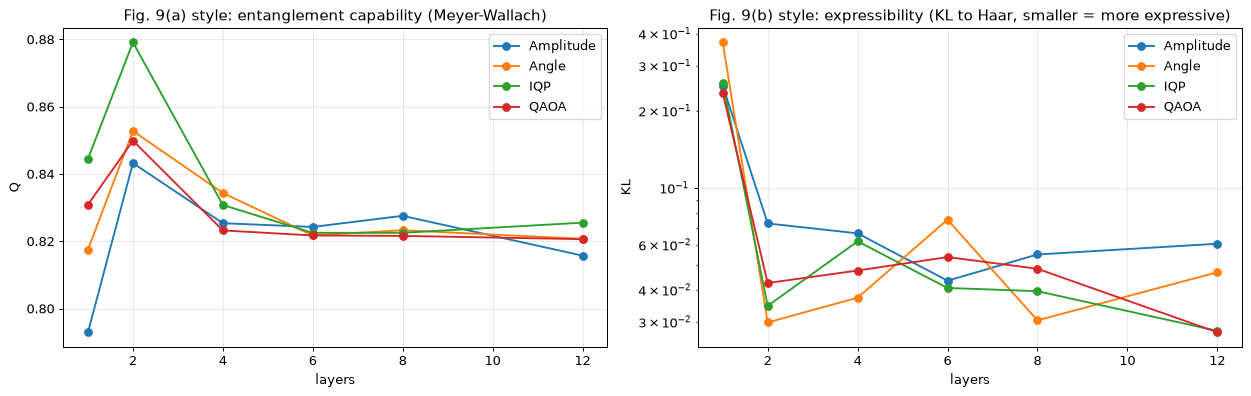

layers        1      2      4      6      8      12
encoding                                           
Amplitude  0.793  0.843  0.825  0.824  0.828  0.816
Angle      0.818  0.853  0.834  0.822  0.823  0.821
IQP        0.844  0.879  0.831  0.823  0.823  0.826
QAOA       0.831  0.850  0.823  0.822  0.822  0.821
layers        1      2      4      6      8      12
encoding                                           
Amplitude  0.251  0.073  0.066  0.043  0.055  0.061
Angle      0.370  0.030  0.037  0.075  0.030  0.047
IQP        0.258  0.035  0.062  0.041  0.039  0.028
QAOA       0.235  0.043  0.048  0.054  0.048  0.027


In [23]:
def haar_bin_probs(N, bins):
    edges = np.linspace(0, 1, bins + 1)
    return (1 - edges[:-1]) ** (N - 1) - (1 - edges[1:]) ** (N - 1)

def meyer_wallach(state, n):
    psi = state.reshape([2] * n); q = 0.0
    for j in range(n):
        m = np.moveaxis(psi, j, 0).reshape(2, -1)
        rho = m @ m.conj().T
        q += np.real(np.trace(rho @ rho))
    return 2.0 * (1.0 - q / n)

def expr_ent(enc, L, n=4, pairs=EXPR_PAIRS, seed=SEED, bins=75):
    r = np.random.default_rng(seed)
    qn = make_qnode(enc, "strong", n, L, output="state")
    d = DS["CICIoT2023"]; Xtr = d.select(n)[0]["tr"]
    sh = weight_shapes(enc, "strong", n, L)
    def rnd_state():
        x = torch.tensor(Xtr[r.integers(len(Xtr))], dtype=torch.float32)
        ws = [torch.tensor(r.uniform(-np.pi, np.pi, size=sh[k]), dtype=torch.float32) for k in sh]
        return qn(x, *ws).detach().numpy().astype(complex)
    fid, ent = [], []
    for _ in range(pairs):
        a, b = rnd_state(), rnd_state()
        fid.append(abs(np.vdot(a, b)) ** 2); ent += [meyer_wallach(a, n), meyer_wallach(b, n)]
    h, _ = np.histogram(fid, bins=np.linspace(0, 1, bins + 1)); p = h / h.sum(); q = haar_bin_probs(2 ** n, bins)
    mask = p > 0; kl = float(np.sum(p[mask] * np.log(p[mask] / q[mask])))
    return kl, float(np.mean(ent))

t_all = time.time(); EXPR = []
for enc in ENCODINGS:
    for L in EXPR_LAYERS:
        kl, ent = expr_ent(enc, L); EXPR.append(dict(encoding=PRETTY[enc], layers=L, KL_to_Haar=kl, entanglement_MW=ent))
EXPR = pd.DataFrame(EXPR)
print(f"Experiment 5 took {(time.time()-t_all)/60:.1f} min")
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
for enc in ENCODINGS:
    s = EXPR[EXPR.encoding == PRETTY[enc]]
    axes[0].plot(s["layers"], s["entanglement_MW"], marker="o", label=PRETTY[enc]); axes[1].plot(s["layers"], s["KL_to_Haar"], marker="o", label=PRETTY[enc])
axes[0].set_title("Fig. 9(a) style: entanglement capability (Meyer-Wallach)"); axes[0].set_xlabel("layers"); axes[0].set_ylabel("Q"); axes[0].legend()
axes[1].set_title("Fig. 9(b) style: expressibility (KL to Haar, smaller = more expressive)"); axes[1].set_xlabel("layers"); axes[1].set_ylabel("KL"); axes[1].set_yscale("log"); axes[1].legend()
plt.tight_layout(); plt.show()
print(EXPR.pivot_table(index="encoding", columns="layers", values="entanglement_MW").round(3).to_string())
print(EXPR.pivot_table(index="encoding", columns="layers", values="KL_to_Haar").round(3).to_string())

## 11. Experiment 6 (extra) - what if the features are NOT scaled?

With features scaled to [0, 1] every task above is nearly trivial: a Random Forest on the same inputs reaches (almost) 100 %, far above the paper's 70 to 89 %. The paper says the features were scaled, but the public notebook that produced the figures reads the selected columns from a pre-cleaned CSV and feeds them to the circuits without any visible scaling.
This extra experiment tests a **hypothesis, not a paper claim**: if the raw (unscaled) top-k features go into the encoders, Angle embedding sees angles of hundreds or thousands of radians (a random-looking phase) and Amplitude embedding keeps only the *direction* of a vector dominated by the largest feature. We repeat the Fig. 8 setting (Amplitude + StronglyEntanglingLayers) and a 4-qubit Angle model on raw features.

In [24]:
def get_data_raw(name, k):
    d = DS[name]; cols = d.order[:k]
    return ({s: d.raw[s][:, cols] for s in ("tr", "va", "te")}, d.y), [d.features[i] for i in cols]

t_all = time.time(); RAWX = []
for name in DS:
    for nq in FIG8_QUBITS:
        dk, _ = get_data_raw(name, 2 ** nq)
        r = train_eval(dk, "amplitude", "strong", nq, N_LAYERS, EPOCHS_FIG8, BATCH_SMALL)
        RAWX.append(dict(dataset=name, model=f"Amplitude, {nq} qubits / {2**nq} features", acc_raw=r["acc"]))
    dk, _ = get_data_raw(name, 4)
    r = train_eval(dk, "angle", "strong", 4, N_LAYERS, EPOCHS_FIG8, BATCH_SMALL)
    RAWX.append(dict(dataset=name, model="Angle (RX), 4 qubits / 4 features", acc_raw=r["acc"]))
RAWX = pd.DataFrame(RAWX)
scaled_ref = F8.assign(model=lambda x: "Amplitude, " + x.qubits.astype(str) + " qubits / " + x.features.astype(str) + " features")[["dataset", "model", "acc_mean"]].rename(columns={"acc_mean": "acc_scaled"})
RAWX = RAWX.merge(scaled_ref, on=["dataset", "model"], how="left")
print(f"Experiment 6 took {(time.time()-t_all)/60:.1f} min")
print(RAWX.round(3).to_string(index=False))

Experiment 6 took 4.6 min
     dataset                             model  acc_raw  acc_scaled
  CICIoT2023  Amplitude, 2 qubits / 4 features    1.000       1.000
  CICIoT2023  Amplitude, 3 qubits / 8 features    0.868       1.000
  CICIoT2023 Amplitude, 4 qubits / 16 features    0.898       1.000
  CICIoT2023 Angle (RX), 4 qubits / 4 features    1.000         NaN
Edge-IIoTset  Amplitude, 2 qubits / 4 features    0.998       0.998
Edge-IIoTset  Amplitude, 3 qubits / 8 features    1.000       1.000
Edge-IIoTset Amplitude, 4 qubits / 16 features    0.998       1.000
Edge-IIoTset Angle (RX), 4 qubits / 4 features    1.000         NaN


## 12. Side-by-side comparison with the paper

Rule (from the project brief): *reproduced* when within 2 accuracy points of the paper's number (or 0.02 for F1); otherwise *not reached* (we are lower) or *exceeded* (we are higher) with the gap; *cannot be checked* when the paper only gives the value in a figure that is not readable; qualitative claims are checked against the ordering in our own tables.

In [25]:
def verdict_num(paper, ours, tol=2.0):
    gap = ours - paper
    if abs(gap) <= tol: return "reproduced"
    return ("exceeded" if gap > 0 else "not reached") + f" ({gap:+.1f} pts)"

rows = []
f8 = F8.set_index(["dataset", "qubits"])["acc_mean"] * 100
if (("CICIoT2023", 2) in f8.index) and (("CICIoT2023", 4) in f8.index):
    for ds, q, paper in [("CICIoT2023", 2, 85.0), ("CICIoT2023", 4, 89.0), ("Edge-IIoTset", 2, 70.0), ("Edge-IIoTset", 4, 73.0)]:
        rows.append(["Fig. 8", f"{ds}, Amplitude + Strongly, {q} qubits / {2**q} features: accuracy", f"{paper:.0f} %", f"{f8[(ds, q)]:.1f} %", verdict_num(paper, f8[(ds, q)])])
best = FIG5.sort_values("val_acc", ascending=False).iloc[0]
top_val = FIG5["val_acc"].max()
yx = FIG5[(FIG5.rotation == "Y") & (FIG5.measurement.isin(["Pauli-X", "Pauli-Y"]))]["val_acc"].max() * 100
rows.append(["Fig. 5", "Angle, Y rotation with Pauli-X or Pauli-Y measurement: best validation accuracy", "93.08 %", f"{yx:.1f} %", verdict_num(93.08, yx)])
zx = FIG5[(FIG5.rotation == "Z")]["val_acc"].mean() * 100
rows.append(["Fig. 5", "Angle, Z rotation (any measurement): accuracy stagnates near 50 %", "about 50 %", f"{zx:.1f} % (mean over the measurements tried)", "reproduced" if abs(zx - 50) <= 10 else f"not reproduced ({zx-50:+.1f} pts)"])
rows.append(["Fig. 5", "Best cell of the rotation x measurement grid", "Y rotation with X or Y measurement", f"{best.rotation} rotation with {best.measurement} ({best.val_acc*100:.1f} %)",
             "reproduced" if (yx / 100 >= top_val - 0.01) else "not reproduced (a different cell is clearly better)"])

piv_acc = T4.pivot_table(index="encoding", columns=["dataset", "entangler"], values="acc")
def rank_of(enc, ds, ent):
    s = piv_acc[(ds, ent)]; return int(1 + (s > s[enc] + 0.005).sum())          # tie-aware: gaps under 0.5 pt count as ties
amp_ranks = [rank_of("Amplitude", ds, ent) for ds in DS for ent in ["Strongly", "Basic"]]
rows.append(["Table 4 / text", "Amplitude is among the top two encodings (stable) on both datasets and both entanglers", "qualitative", f"ranks (of 4) = {amp_ranks}", "reproduced" if max(amp_ranks) <= 2 else "partly" if np.mean(amp_ranks) <= 2.5 else "not reached"])
qb = piv_acc[("CICIoT2023", "Basic")]["QAOA"]
rows.append(["Table 4 / text", "QAOA embedding with the weakly entangling circuit is near perfect on the DDoS data (taken as >= 0.97)", "near perfect", f"{qb*100:.1f} %", "reproduced" if qb >= 0.97 else f"not reached ({(qb-0.97)*100:+.1f} pts vs 97 %)"])
iqp_worse = np.mean([piv_acc[(ds, ent)]["IQP"] < piv_acc[(ds, ent)]["Amplitude"] - 0.005 for ds in DS for ent in ["Strongly", "Basic"]])
rows.append(["Table 4 / text", "IQP is weaker than Amplitude in most settings", "qualitative", f"IQP < Amplitude in {iqp_worse*100:.0f} % of the 4 settings", "reproduced" if iqp_worse >= 0.5 else "not reached"])
cic_vs_edge = F8.groupby("dataset")["acc_mean"].mean()
gap_ce = (cic_vs_edge["CICIoT2023"] - cic_vs_edge["Edge-IIoTset"]) * 100
rows.append(["Fig. 8 / text", "DDoS flows (CICIoT2023) are easier than the mixed-attack packets of Edge-IIoTset", "CICIoT2023 > Edge-IIoTset (by 15-16 pts)", f"mean Fig. 8 accuracy {cic_vs_edge['CICIoT2023']*100:.1f} % vs {cic_vs_edge['Edge-IIoTset']*100:.1f} % ({gap_ce:+.1f} pts)", "reproduced" if gap_ce > 2 else "not reached (no CICIoT2023 advantage here)"])
g = FIG7.groupby(["encoding", "layers"])["acc"].mean().unstack()
Lmin, Lmax = min(LAYER_GRID), max(LAYER_GRID)
gain = (g[Lmax] - g[Lmin]) * 100
rows.append(["Fig. 7 / text", "Accuracy rises with depth for Amplitude and QAOA", "qualitative", f"gain {Lmin}->{Lmax} layers: Amplitude {gain['Amplitude']:+.1f}, QAOA {gain['QAOA']:+.1f} pts", "reproduced" if (gain["Amplitude"] > 0 and gain["QAOA"] > 0) else "not reached"])
rows.append(["Fig. 7 / text", "Angle embedding gains little from extra layers", "qualitative", f"gain {Lmin}->{Lmax} layers: Angle {gain['Angle']:+.1f} pts (others {gain.drop('Angle').mean():+.1f})", "reproduced" if gain["Angle"] <= gain.drop("Angle").max() else "not reached"])
ex_last = EXPR[EXPR.layers == max(EXPR_LAYERS)].set_index("encoding")
rows.append(["Fig. 9a / text", "Amplitude has the highest entanglement capability", "Amplitude highest", f"MW at {max(EXPR_LAYERS)} layers: " + ", ".join(f"{k} {v:.2f}" for k, v in ex_last['entanglement_MW'].items()),
             "reproduced" if ex_last["entanglement_MW"].idxmax() == "Amplitude" else f"not reached (highest = {ex_last['entanglement_MW'].idxmax()})"])
rows.append(["Fig. 9b / text", "Amplitude has the lowest expressibility score (text wording)", "ambiguous", f"KL at {max(EXPR_LAYERS)} layers: " + ", ".join(f"{k} {v:.3f}" for k, v in ex_last['KL_to_Haar'].items()),
             "cannot be checked (wording ambiguous; KL values shown)"])
m_scaled = RAWX["acc_scaled"].mean() * 100; m_raw = RAWX.loc[RAWX["model"].str.startswith("Amplitude"), "acc_raw"].mean() * 100
rows.append(["Extra (hypothesis)", "Unscaled inputs (as in the public code) pull accuracy toward the paper's 70-89 %", "70-89 % (Fig. 8)", f"Amplitude raw {m_raw:.1f} % vs scaled {RAWX.loc[RAWX['model'].str.startswith('Amplitude'), 'acc_scaled'].mean()*100:.1f} %", "informative only (not a paper claim)"])
rows.append(["Table 4", "Exact accuracy / precision / F1 / recall per encoding and entangler", "values only in the table image", "see section 6", "cannot be checked"])
rows.append(["Fig. 6, 10", "Exact epoch curves and radar values", "figure only", "see sections 6", "cannot be checked"])
CMP = pd.DataFrame(rows, columns=["source", "claim", "paper", "this notebook", "verdict"])
pd.set_option("display.max_colwidth", 120); pd.set_option("display.width", 250)
print(CMP.to_string(index=False))

            source                                                                                                 claim                                    paper                                                        this notebook                                                verdict
            Fig. 8                                     CICIoT2023, Amplitude + Strongly, 2 qubits / 4 features: accuracy                                     85 %                                                              100.0 %                                   exceeded (+15.0 pts)
            Fig. 8                                    CICIoT2023, Amplitude + Strongly, 4 qubits / 16 features: accuracy                                     89 %                                                              100.0 %                                   exceeded (+11.0 pts)
            Fig. 8                                   Edge-IIoTset, Amplitude + Strongly, 2 qubits / 4 features: accuracy                      

In [26]:
# Classical baselines next to the quantum models (same inputs, same test split)
q_best = T4.sort_values("acc", ascending=False).groupby("dataset").head(1)[["dataset", "encoding", "entangler", "acc", "prec", "rec", "f1"]]
print("Best quantum model per dataset:"); print(q_best.round(3).to_string(index=False))
print("\nClassical baselines:"); print(BASE.round(3).to_string(index=False))
print("\nQuantum minus best classical (8-feature) accuracy:")
for ds in DS:
    b = BASE[(BASE.dataset == ds) & BASE.model.str.contains("top-k features")]["acc"].max()
    q = T4[T4.dataset == ds]["acc"].max(); print(f"  {ds}: best quantum {q:.3f} vs best classical {b:.3f}  ({(q-b)*100:+.1f} pts)")
print("\nWall-clock: quantum training of one run is typically", f"{T4['fit_s'].median():.0f} s versus well under a second for the classical models.")

Best quantum model per dataset:
     dataset  encoding entangler  acc  prec  rec  f1
  CICIoT2023 Amplitude  Strongly  1.0   1.0  1.0 1.0
Edge-IIoTset     Angle  Strongly  1.0   1.0  1.0 1.0

Classical baselines:
     dataset                               model  acc  prec  rec  f1  seconds
  CICIoT2023       RandomForest (top-k features)  1.0   1.0  1.0 1.0    1.152
  CICIoT2023        SVC rbf C=1 (top-k features)  1.0   1.0  1.0 1.0    0.044
  CICIoT2023 LogisticRegression (top-k features)  1.0   1.0  1.0 1.0    0.045
  CICIoT2023     MLP k-k-1 tanh (top-k features)  1.0   1.0  1.0 1.0    2.267
  CICIoT2023      RandomForest (all 39 features)  1.0   1.0  1.0 1.0      NaN
Edge-IIoTset       RandomForest (top-k features)  1.0   1.0  1.0 1.0    1.134
Edge-IIoTset        SVC rbf C=1 (top-k features)  1.0   1.0  1.0 1.0    0.029
Edge-IIoTset LogisticRegression (top-k features)  1.0   1.0  1.0 1.0    0.052
Edge-IIoTset     MLP k-k-1 tanh (top-k features)  1.0   1.0  1.0 1.0    1.241
Edge-II

## 13. Reading the paper critically

1. **The headline question (does the encoding matter?) is answered, but with one seed per cell.** The paper's Table 4 has no error bars and no repeated runs; differences of one or two accuracy points between encodings are inside seed-to-seed noise on test sets of a few thousand rows. Here Fig. 8 is repeated over 2 seeds; the rest uses one seed per cell, so treat small gaps as ties.
2. **Hyper-parameters that decide the outcome are not reported.** Number of training rows, learning rate, whether the features were first scaled to [0, 1] or left raw (the public notebook feeds the XGBoost-selected columns directly), the exact measured Pauli operator (text: Pauli-Z, code: Pauli-X for two encodings) and the number of qubits of the layer sweep are all missing or contradictory. With about 100 times fewer optimiser steps than a full-dataset run, the learning rate used here is larger than Keras' default; the 1e-3 check in section 9 shows how much that matters.
3. **"IQP" and "QAOA" embeddings are not designed as data encodings** (the paper says so itself). The QAOA embedding brings its own trainable parameters, so its better accuracy at a given depth may simply be extra capacity, not a better encoding.
4. **Z rotations cannot work.** Rotating |0> about Z only changes a global phase; Fig. 5's 50 % for Z rotations is therefore trivial and says nothing about measurement bases. The headline 93.08 % is a validation accuracy of a single run.
5. **Amplitude embedding on 8 features uses only 8 of 256 amplitudes.** On 8 qubits it is effectively a 3-qubit encoding followed by 8-qubit trainable layers; the fully-used register only appears in the Fig. 8 sweep.
6. **No quantum advantage claim, and none can be made.** Everything is state-vector simulation; a Random Forest on the same eight features is faster and at least as accurate, as the baseline table shows. Hardware noise and shot noise are not studied (the paper lists this as future work).
7. **Ceiling effect.** With the pipeline as described (features scaled to [0, 1], top-k by XGBoost / ANOVA, a balanced 50 / 50 sample) almost every strongly-entangled model reaches 100 % here, and so do a logistic regression and a Random Forest on the same inputs. The paper's 70 to 89 % therefore cannot be an information limit of the selected features; it points to optimisation budget, scaling or sampling differences. The only differences that survive in our runs are failures to train: Angle embedding with the Basic entangler stays at chance (RX embedding, RX entangler and Pauli-X measurement commute, so nothing can be learned), and Amplitude + Basic is partial. The extra experiment on unscaled features (section 11) gives 87-90 % for Amplitude on CICIoT2023 with 8 and 16 features, close to the paper's 85-89 %, but 100 % with 4 features and about 100 % on Edge-IIoTset, so unscaled inputs explain the CICIoT2023 numbers at best partly.
8. **Datasets are not exactly the paper's.** Mirrors, sampling and the 39 versus 38 CICIoT2023 features differ, and the balanced 50 / 50 sample is much easier than the real class mix (CICIoT2023 is more than 97 % attack traffic), so accuracies are not directly comparable to a real deployment. At 12 layers all four encodings have a Meyer-Wallach value near 0.82 (saturation), so Fig. 9's separation between encodings is only visible at small depth.
9. **Expressibility and entanglement figures depend on the sampling distribution** (inputs from data versus random angles, number of pairs, qubit count), none of which is stated.

## 14. Exercises

1. Run `FAST_MODE = False` and add two more seeds to the Table 4 grid. Which differences between encodings survive a paired comparison?
2. Replace the feature scaling [0, 1] by [0, pi] for Angle embedding. Does the accuracy of the Y rotation change, and why does the encoding range matter for a periodic gate?
3. Fix the number of **trainable parameters** (not the depth) across the four encodings, for instance by removing the QAOA embedding's own weights, and redo Fig. 7. Is QAOA still ahead?
4. Add shot noise (`default.qubit` with `shots=1000` and parameter-shift gradients) or a `default.mixed` depolarising channel and see which encoding degrades first.
5. Train a purely classical network with the same number of parameters on the same eight features and the same budget. Where do the quantum models stand when all budgets are equal?